# OPERA Advanced Interactive Activities (AIA) Set 1 — Workshop
---
## Day 2: SST Visualization & Anomaly Detection

**Content creator:** Babette C. Tchonang

**Content editors:**

**Production editors**

**Content coordinator**: Arielle Stella Imbol

## About This MOOC

This tutorial is part of the **OPERA Capacity Development**, developed and led jointly by **GGOSSS** and **ICMPA - UNESCO CHAIR**.

The OPERA project is **financed by the European Union** and implemented by **Mercator Ocean International**, in the framework of the **Ocean Prediction Decade Collaborative Centre (OceanPrediction DCC)**.

> *Funded by the European Union. Views and opinions expressed are however those of the author(s) only and do not necessarily reflect those of the European Union. The European Union cannot be held responsible for them.*

---

### Day 2 Schedule (09:00–18:00)

| Time | Format | Activity | Notebook |
|------|--------|----------|----------|
| 09:00–09:20 | Opening Plenary | Day 1 recap — 5-question live poll | — |
| 09:20–10:00 | Opening Plenary | Expert Demonstration — **NB1: SST Visualization** | Section 1 |
| 10:00–10:15 | Break | | |
| 10:15–12:15 | Subgroups | Guided Practice — custom SST maps for **your area** | Section 1 |
| 12:15–12:45 | Reconvergence Plenary | SST Map Gallery Walk | Discussion |
| 12:45–13:45 | Lunch | | |
| 13:45–14:30 | Opening Plenary | Expert Demonstration — **NB2: Anomaly Detection** | Section 2 |
| 14:30–16:15 | Subgroups | Collaborative analysis of your own area | Section 2 |
| 16:15–16:30 | Break | | |
| 16:30–17:30 | Reconvergence Plenary | Sub-region reporting — 8–10 min per subgroup | Section 3 |
| 17:30–18:00 | Wrap-Up Plenary | Day 2 Reflection & Day 3 Preview | Section 4 |

> **Facilitators:** every section header repeats its slot. If you are behind by 14:30, cut the Extension tasks rather than the subgroup analysis — the reporting slot at 16:30 is fixed.

---

### Day 2 Learning Objectives

1. Open, explore and visualize SST using `xarray`, `matplotlib` and `cartopy`
2. Compute a monthly climatology and derive anomaly fields
3. Identify seasonal patterns and interannual variability in **your own study area**
4. Connect observed SST patterns to the physics of MOOC Module 2 and forecast interpretation in Module 6
5. Work confidently inside a notebook you did not write

---

### Today is different from Day 1

Yesterday everyone worked the same Gulf of Guinea domain. **Today your subgroup takes its own area.**

| Area | Region | Regime |
|------|--------|--------|
| **1** | Mauritania / Senegal | Eastern boundary upwelling — alongshore trades |
| **2** | Gulf of Guinea (east) | Equatorial / monsoon, river outflow |
| **3** | Agulhas | Western boundary current — rings, marine heatwaves |

Set `ACTIVE_ZONE` in Section 0 to your group number. **Nothing else needs changing** — domain, files, colour scales, reference points and titles all follow.

> **Area 3 is in the southern hemisphere.** JJA is *winter* there. When the groups report back at 16:30, be precise about whose season you mean.

> **Prerequisite:** Day 1 complete, with data in `OPERA_Workshop_Data/data/` on your Drive.

---


---

##  Section 0 — Setup & Reconnect

*Setup Block  |  09:00–09:20  (20 min — everyone, hands on)*

Reconnects to the same Drive folder as Day 1. Nothing is downloaded today — all four datasets are already staged.

---


In [ ]:
# ============================================================
# STEP 0.1 — MOUNT GOOGLE DRIVE  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Reconnects to the same Drive folder used on Day 1.
# HDF5 file locking is disabled BEFORE any NetCDF is opened —
# Drive's FUSE layer does not support it, and reads fail or
# hang without this. Safe here because we only ever read.
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

DATA_DIR   = '/content/drive/MyDrive/OPERA_Workshop_Data/data'
OUTPUT_DIR = '/content/drive/MyDrive/OPERA_Workshop_Data/output/Day2'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('==> Google Drive mounted')
print(f'   Data   : {DATA_DIR}')
print(f'   Output : {OUTPUT_DIR}')
print()

if os.path.isdir(DATA_DIR):
    nc = sorted(f for f in os.listdir(DATA_DIR) if f.endswith('.nc'))
    print(f'   {len(nc)} NetCDF files found:')
    for f in nc:
        print(f'     {f:<30} {os.path.getsize(os.path.join(DATA_DIR, f))/1e6:>7.0f} MB')
else:
    print('   !! DATA_DIR not found — check the shared-folder shortcut in your Drive.')


Mounted at /content/drive
==> Google Drive mounted
   Data   : /content/drive/MyDrive/OPERA_Workshop_Data/data
   Output : /content/drive/MyDrive/OPERA_Workshop_Data/output/Day2

   12 NetCDF files found:
     AGU_SSH_altimetry.nc               314 MB
     AGU_SST_reanalysis.nc              491 MB
     AGU_currents.nc                    196 MB
     AGU_wind_monthly.nc                  2 MB
     GOG_SSH_altimetry.nc               982 MB
     GOG_SST_reanalysis.nc             1534 MB
     GOG_currents.nc                    614 MB
     GOG_wind_monthly.nc                  4 MB
     MRS_SSH_altimetry.nc               173 MB
     MRS_SST_reanalysis.nc              270 MB
     MRS_currents.nc                    108 MB
     MRS_wind_monthly.nc                  1 MB


In [ ]:
# ============================================================
# STEP 0.2 — CHECK & INSTALL PACKAGES  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Colab resets its environment between sessions. Packages you
# installed on Day 1 are GONE today — only your Drive persists.
# So we check again before importing anything.
#
# cartopy and netCDF4 are the two that are never pre-installed.
# ============================================================

import importlib, subprocess, sys

REQUIRED = [
    ('xarray',     'xarray'),
    ('numpy',      'numpy'),
    ('pandas',     'pandas'),
    ('scipy',      'scipy'),
    ('matplotlib', 'matplotlib'),
    ('cartopy',    'cartopy'),
    ('netCDF4',    'netCDF4'),
    ('h5netcdf',   'h5netcdf'),
    ('h5py',       'h5py'),
    ('dask',       'dask'),
]

print('Checking packages...\n')
missing = []
for import_name, pip_name in REQUIRED:
    try:
        importlib.import_module(import_name)
        print(f'   [ok  ]  {pip_name}')
    except ImportError:
        print(f'   [miss]  {pip_name}')
        missing.append(pip_name)

if missing:
    print(f'\nInstalling {len(missing)} package(s) — takes 1-3 minutes...')
    failed = []
    for pkg in missing:
        # One failure must not stop the rest. Report and carry on.
        r = subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'],
                           capture_output=True, text=True)
        if r.returncode == 0:
            print(f'   [ok  ]  {pkg} installed')
        else:
            failed.append(pkg)
            tail = (r.stderr or r.stdout).strip().splitlines()
            print(f'   [FAIL]  {pkg}')
            if tail:
                print(f'           {tail[-1][:70]}')
    print()
    if failed:
        print(f'   ==> {len(failed)} package(s) would not install: {", ".join(failed)}')
        print('       Try installing by hand in a new cell, e.g.:')
        print(f'           !pip install {failed[0]}')
        print('       Then tell your Subgroup Instructor.')
    else:
        print('   ==> All installed.')
    print()
    print('   ==> If the next cell still fails on an import:')
    print('       Runtime -> Restart session, then re-run from Step 0.1.')
    print('       cartopy sometimes needs a restart to register.')
else:
    print('\n==> All packages ready — go to Step 0.3.')

Checking packages...

   [ok  ]  xarray
   [ok  ]  numpy
   [ok  ]  pandas
   [ok  ]  scipy
   [ok  ]  matplotlib
   [miss]  cartopy
   [miss]  netCDF4
   [ok  ]  h5netcdf
   [ok  ]  h5py
   [ok  ]  dask

Installing 2 package(s) — takes 1-3 minutes...
   [ok  ]  cartopy installed
   [ok  ]  netCDF4 installed

   ==> All installed.

   ==> If the next cell still fails on an import:
       Runtime -> Restart session, then re-run from Step 0.1.
       cartopy sometimes needs a restart to register.


### 0.3 — Your study area

*within Setup Block  |  09:00–09:20*

The same configuration block as Day 1, with one difference: **`PHASE` is now `'zone'`**, so you work your own area rather than the shared domain.

**Set `ACTIVE_ZONE` to your group number and run.** Everything downstream follows from it.

---


In [ ]:
# ============================================================
# STEP 0.3 — STUDY AREA CONFIGURATION
# ─────────────────────────────────────────────────────────────
# Day 1 ran PHASE = 'shared' — everyone on the full Gulf of
# Guinea box. Today runs PHASE = 'zone' — your own area.
#
# CHANGE ONE LINE: ACTIVE_ZONE.
# ============================================================

# ---------- Day 1's shared teaching domain (for reference) ----------
SHARED = dict(
    name   = 'Gulf of Guinea (shared domain)',
    prefix = 'GOG',
    lon    = (-10.0, 15.0),
    lat    = ( -5.0, 10.0),
)

# ---------- The three subgroup study areas ----------
ZONES = {
    '1': dict(
        name        = 'Mauritania / Senegal',
        prefix      = 'MRS',
        lon         = (-21.0, -15.0),
        lat         = ( 14.0,  25.0),
        regime      = 'Canary Eastern Boundary Upwelling System',
        wind_story  = 'Alongshore NE trades drive offshore Ekman transport '
                      '-> strong coastal upwelling',
        sst_range   = (16, 26), sst_snap = (15, 25), ts_ylim = (14, 30),
        anom_lim    = 2.0,
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [(-17.2, 21.0, 'Nouadhibou  (Mauritania)'),
                       (-16.8, 19.0, 'Nouakchott  (Mauritania)'),
                       (-17.8, 14.7, 'Dakar  (Senegal)')],
    ),
    '2': dict(
        name        = 'Gulf of Guinea',
        prefix      = 'GOG',              # slice of the shared domain
        lon         = (  5.0, 15.0),
        lat         = ( -5.0,  5.0),
        regime      = 'Equatorial / monsoon, large river outflow',
        wind_story  = 'Monsoon southwesterlies; Coriolis vanishes at the '
                      'equator, so Ekman theory breaks down here',
        sst_range   = (20, 25), sst_snap = (22, 29), ts_ylim = (22, 31),
        anom_lim    = 1.5,
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [( 6.0,  3.5, 'Bight of Biafra'),
                       ( 9.0,  0.5, 'Port-Gentil  (Gabon)'),
                       (11.5, -4.5, 'Pointe-Noire  (Congo)')],
    ),
    '3': dict(
        name        = 'Agulhas',
        prefix      = 'AGU',
        lon         = ( 15.0,  30.0),
        lat         = (-38.0, -30.0),
        regime      = 'Western boundary current — rings, marine heatwaves',
        wind_story  = 'Westerlies are strong, but this current is inertial: '
                      'wind is NOT the local driver',
        sst_range   = (14, 24), sst_snap = (12, 24), ts_ylim = (12, 28),
        anom_lim    = 2.5,
        hemisphere  = 'S', upwell_season = 'DJF',
        ref_points  = [(18.0, -34.6, 'Cape Point  (South Africa)'),
                       (22.5, -34.9, 'Mossel Bay  (South Africa)'),
                       (27.5, -33.6, 'Port Edward  (South Africa)')],
    ),
}

# ─────────────────────────────────────────────────────────────
# YOUR SUBGROUP — change this one line
# ─────────────────────────────────────────────────────────────
ACTIVE_ZONE = '3'          # <- '1', '2' or '3'
PHASE       = 'zone'       # Day 2 works the subgroup areas

Z = ZONES[ACTIVE_ZONE]
D = SHARED if PHASE == 'shared' else Z

LON_MIN, LON_MAX = D['lon']
LAT_MIN, LAT_MAX = D['lat']
DOMAIN_NAME      = D['name']
FILE_PREFIX      = D['prefix']

SST_VMIN,  SST_VMAX  = Z['sst_range']
SNAP_VMIN, SNAP_VMAX = Z['sst_snap']
TS_YMIN,   TS_YMAX   = Z['ts_ylim']
ANOM_LIM             = Z['anom_lim']
ZONE_NAME  = Z['name']
REF_POINTS = Z['ref_points']

DATE_START = '2010-01-01'
DATE_END   = '2023-12-31'
COLORS = ['#E74C3C', '#27AE60', '#8E44AD']
MONTH_NAMES = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']
MONTHS_SHORT = ['J','F','M','A','M','J','J','A','S','O','N','D']

print(f'==> AREA {ACTIVE_ZONE} — {ZONE_NAME}')
print(f'   Regime : {Z["regime"]}')
print(f'   Wind   : {Z["wind_story"]}')
print(f'   Box    : lon [{LON_MIN}, {LON_MAX}]   lat [{LAT_MIN}, {LAT_MAX}]')
print(f'   Files  : {FILE_PREFIX}_*.nc')
print(f'   Period : {DATE_START} -> {DATE_END}')
print()
if Z['hemisphere'] == 'S':
    print('   !! SOUTHERN HEMISPHERE')
    print('      JJA is WINTER for you, DJF is SUMMER.')
    print('      Every seasonal label below means the opposite of')
    print('      what it means for Areas 1 and 2. Say so when you report.')
else:
    print(f'   Upwelling / cool season for your area: {Z["upwell_season"]}')
print()
if Z['prefix'] == SHARED['prefix']:
    print('   NOTE: your area sits inside the shared domain, so you read')
    print('         the same GOG_*.nc files and narrow the bounding box.')


==> AREA 3 — Agulhas
   Regime : Western boundary current — rings, marine heatwaves
   Wind   : Westerlies are strong, but this current is inertial: wind is NOT the local driver
   Box    : lon [15.0, 30.0]   lat [-38.0, -30.0]
   Files  : AGU_*.nc
   Period : 2010-01-01 -> 2023-12-31

   !! SOUTHERN HEMISPHERE
      JJA is WINTER for you, DJF is SUMMER.
      Every seasonal label below means the opposite of
      what it means for Areas 1 and 2. Say so when you report.



### 0.4 — The universal loader

*within Setup Block  |  09:00–09:20*

Your data may be arranged two ways on disk, and both work:

| | |
|---|---|
| **Staged** — one file per product | `GOG_SST_reanalysis.nc`, all 14 years |
| **Self-downloaded** — one file per year | `MRS_daily_years/MRS_SST_2010.nc` … |

`open_product()` checks for year-files first and falls back to the staged file, so every cell below runs identically whichever route you took on Day 1.

---


In [ ]:
# ============================================================
# STEP 0.5 — UNIVERSAL LOADER
# ─────────────────────────────────────────────────────────────
# Reads staged single files OR self-downloaded year-files.
# Also normalises the two services' naming conventions:
#   CMEMS -> time axis 'time',        latitude ascending
#   ERA5  -> time axis 'valid_time',  latitude descending
#
# Imports what it needs, so it works whatever order you run in.
# ============================================================

import os, glob
import xarray as xr

os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'


def zone_files(prefix):
    """The four file paths for a given domain prefix."""
    return dict(
        SST  = os.path.join(DATA_DIR, f'{prefix}_SST_reanalysis.nc'),
        SSH  = os.path.join(DATA_DIR, f'{prefix}_SSH_altimetry.nc'),
        CURR = os.path.join(DATA_DIR, f'{prefix}_currents.nc'),
        WIND = os.path.join(DATA_DIR, f'{prefix}_wind_monthly.nc'),
    )


def normalise(ds):
    """Make ERA5 and CMEMS files behave identically."""
    if 'valid_time' in ds.dims and 'time' not in ds.dims:
        ds = ds.rename({'valid_time': 'time'})
    return ds.drop_vars(['number', 'expver'], errors='ignore')


def open_product(kind, prefix=None, verbose=True):
    """Open one product for the current area, whatever shape it is in."""
    pfx     = prefix or FILE_PREFIX
    ydir    = os.path.join(DATA_DIR, f'{pfx}_daily_years')
    chunks  = sorted(glob.glob(os.path.join(ydir, f'{pfx}_{kind}_*.nc')))

    if chunks:
        if verbose:
            yrs = [os.path.basename(c).rsplit('_', 1)[1][:4] for c in chunks]
            print(f'   {kind}: {len(chunks)} year-files ({yrs[0]}-{yrs[-1]}) [self-downloaded]')
        return normalise(xr.open_mfdataset(chunks, combine='by_coords',
                                           chunks={'time': 90}, engine='h5netcdf'))

    single = zone_files(pfx)[kind]
    if os.path.exists(single):
        if verbose:
            print(f'   {kind}: 1 file, {os.path.getsize(single)/1e6:.0f} MB [staged]')
        return normalise(xr.open_dataset(single, chunks={'time': 90},
                                         engine='h5netcdf'))

    raise FileNotFoundError(
        f'No {kind} data for area prefix {pfx}.\n'
        f'   Looked in : {ydir}\n'
        f'   and       : {single}\n'
        f'   -> Ask your Subgroup Instructor for the staged copy.')


def surface(da):
    """Drop a singleton depth axis so 3-D current fields plot as 2-D."""
    if 'depth' in da.dims:
        da = da.isel(depth=0)
    return da.squeeze(drop=True)


print(f'==> Loader ready for area {ACTIVE_ZONE} ({FILE_PREFIX})')
print()
print('   Checking what is available:')
for k in ['SST', 'SSH', 'CURR', 'WIND']:
    try:
        d = open_product(k, verbose=True)
        print(f'        -> {d.sizes.get("time", "?")} timesteps')
        d.close()
    except FileNotFoundError:
        print(f'   {k}: MISSING — you cannot proceed without this')
    except Exception as e:
        print(f'   {k}: could not open — {type(e).__name__}: {e}')

==> Loader ready for area 3 (AGU)

   Checking what is available:
   SST: 1 file, 491 MB [staged]
        -> 5113 timesteps
   SSH: 1 file, 314 MB [staged]
        -> 5113 timesteps
   CURR: 1 file, 196 MB [staged]
        -> 5113 timesteps
   WIND: 1 file, 2 MB [staged]
        -> 168 timesteps


---
---

#  Section 1 — SST Visualization

*Demonstration 09:20–10:00  |  Guided practice 10:15–12:15*

Yesterday you made maps of the shared domain. Today you make them for **your own area**, and the differences between areas are the point.

**What you will produce:**

1. Time-mean SST — the climatological pattern
2. Four seasonal maps — DJF, MAM, JJA, SON
3. A single-year map — how one year departs from the mean
4. An annotated map of your area, ready for the gallery walk

> **MOOC connection:** Modules 5 & 6 — gridded data formats and reading spatial patterns.

---


### 1.1 — Load SST for your area

*within Demonstration  |  09:20–10:00*

Two steps that always go together: **open**, then **convert units**. Satellite L4 SST is published in Kelvin. Plotting it without converting is the single most common error in ocean data work.

---


In [ ]:
# ============================================================
# 1.1 — LOAD SST AND CONVERT TO CELSIUS
# ─────────────────────────────────────────────────────────────
# chunks={'time': 90} uses Dask so the 14-year record is read
# lazily rather than pulled into memory all at once.
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

print('Loading SST...')
ds_sst = open_product('SST')

sst_all = ds_sst['analysed_sst'] - 273.15
sst_all.attrs['units']     = 'degC'
sst_all.attrs['long_name'] = 'Sea Surface Temperature'

# Narrow to YOUR area. Area 2 reads the shared file and clips;
# Areas 1 and 3 read their own file, and this is a no-op.
sst = sst_all.sel(latitude  = slice(LAT_MIN, LAT_MAX),
                  longitude = slice(LON_MIN, LON_MAX))

print()
print(f'==> SST ready for {ZONE_NAME}')
print(f'   Shape      : {sst.shape}   (time x lat x lon)')
print(f'   Time range : {str(sst.time.values[0])[:10]} -> {str(sst.time.values[-1])[:10]}')
print(f'   Lat        : {float(sst.latitude.min()):.2f} to {float(sst.latitude.max()):.2f}')
print(f'   Lon        : {float(sst.longitude.min()):.2f} to {float(sst.longitude.max()):.2f}')
print()

first = float(sst.isel(time=0).mean().values)
print(f'   Spatial mean, first timestep: {first:.2f} degC')
if 0 < first < 35:
    print('   Physically plausible for sea surface water.')
else:
    print('   !! That value looks wrong — did the Kelvin conversion run?')


Loading SST...
   SST: 1 file, 491 MB [staged]

==> SST ready for Agulhas
   Shape      : (5113, 160, 300)   (time x lat x lon)
   Time range : 2010-01-01 -> 2023-12-31
   Lat        : -37.97 to -30.02
   Lon        : 15.02 to 29.98

   Spatial mean, first timestep: 20.77 degC
   Physically plausible for sea surface water.


### 1.2 — The time-mean map

*within Demonstration  |  09:20–10:00*

`.mean('time')` collapses 14 years into one field: the climatological SST of your area.

> **This is the slow step.** Averaging 5,113 daily fields means reading the whole file from Drive. `.compute()` does it once and keeps the result, so every map after this is fast.

---


Computing the 14-year mean (slow — reads the whole file)...
Done. Range 12.42 to 24.00 degC



/usr/local/lib/python3.12/dist-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


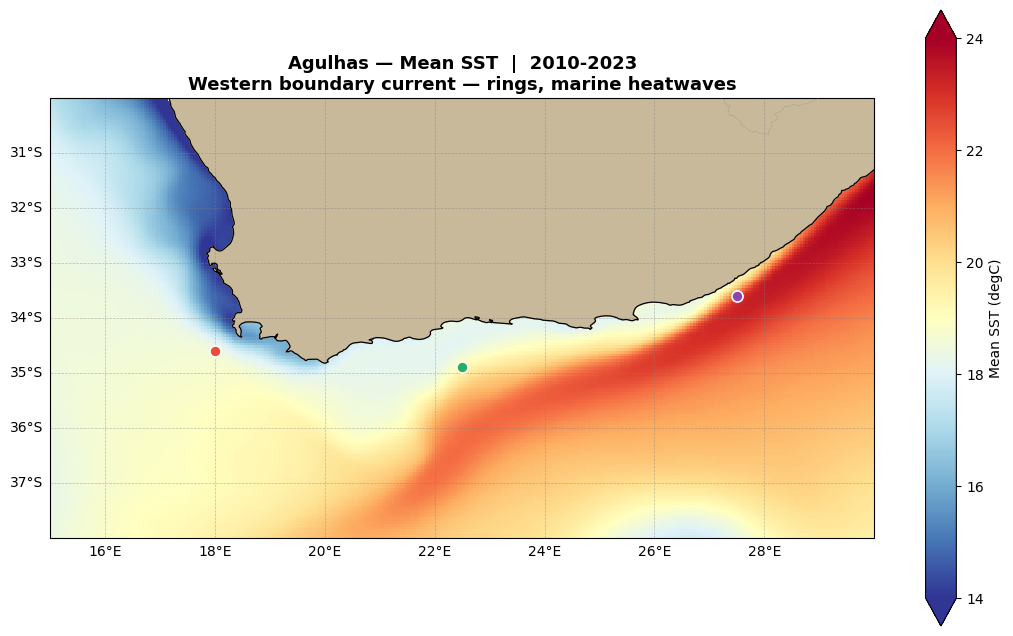

==> Saved: Day2_SST_mean_AGU.png
   Area mean SST: 19.57 degC

   Gallery walk: how does your area compare with the other two?


In [ ]:
# ============================================================
# 1.2 — TIME-MEAN SST MAP
# ─────────────────────────────────────────────────────────────
# .compute() forces the calculation ONCE and holds the result.
# Without it, every plot re-reads the file from Drive.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

print('Computing the 14-year mean (slow — reads the whole file)...')
sst_mean = sst.mean('time').compute()
print(f'Done. Range {float(sst_mean.min()):.2f} to {float(sst_mean.max()):.2f} degC')
print()

fig, ax = plt.subplots(figsize=(11, 8),
                       subplot_kw={'projection': ccrs.PlateCarree()})

sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=SST_VMIN, vmax=SST_VMAX, extend='both',
              cbar_kwargs={'label': 'Mean SST (degC)', 'shrink': 0.8, 'pad': 0.05},
              add_labels=False)

ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, color='black', zorder=3)
ax.add_feature(cfeature.BORDERS, linewidth=0.4, linestyle=':', edgecolor='gray', zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray',
                  alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False

for (rlon, rlat, rname), col in zip(REF_POINTS, COLORS):
    ax.plot(rlon, rlat, 'o', markersize=8, color=col,
            markeredgecolor='white', markeredgewidth=1.2,
            transform=ccrs.PlateCarree(), zorder=6)

ax.set_title(f'{ZONE_NAME} — Mean SST  |  {DATE_START[:4]}-{DATE_END[:4]}\n'
             f'{Z["regime"]}',
             fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_SST_mean_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f'==> Saved: Day2_SST_mean_{FILE_PREFIX}.png')
print(f'   Area mean SST: {float(sst_mean.mean()):.2f} degC')
print()
print('   Gallery walk: how does your area compare with the other two?')


### 1.3 — Four seasons

*within Guided Practice  |  10:15–12:15*

The mean hides the seasons. `groupby('time.season')` splits the record into DJF, MAM, JJA and SON.

> **Areas 1 and 2:** JJA is your upwelling season — expect it coldest.
> **Area 3:** JJA is your *winter*. Also coldest, but for an entirely different reason. That distinction is worth making explicitly when you report.

---


Computing seasonal means...
Done.



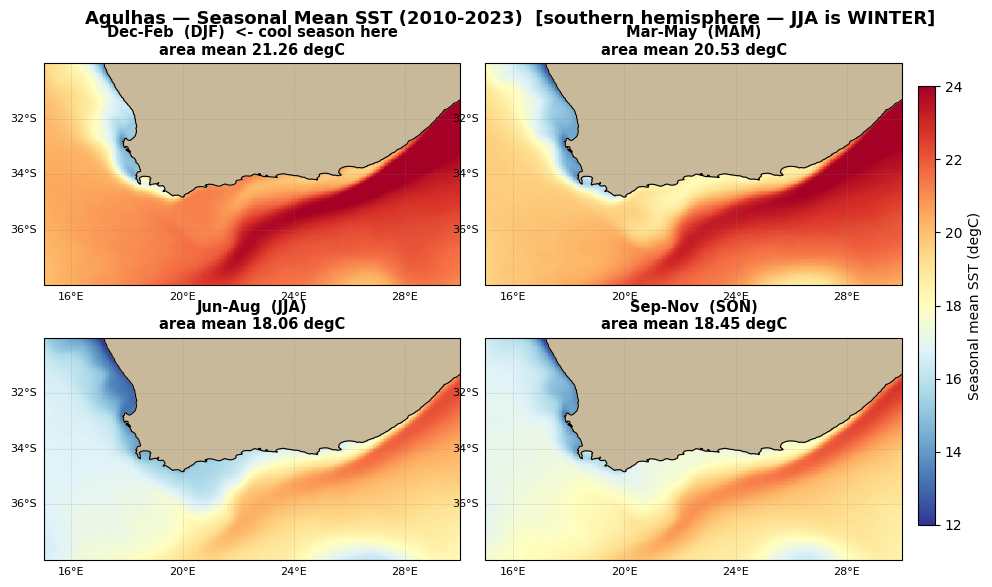

Figure sized 10.6 x 6.1 in for a domain aspect of 1.88

Seasonal area means:
   DJF   21.26 degC  #########################################
   MAM   20.53 degC  ###############################
   JJA   18.06 degC  #
   SON   18.45 degC  #####

   Warmest: DJF   Coolest: JJA
   Seasonal range: 3.20 degC


In [ ]:
# ============================================================
# 1.3 — SEASONAL MEAN SST
# ─────────────────────────────────────────────────────────────
# All four panels share one colour scale, so the seasons are
# genuinely comparable. Independent scales would make every
# panel look the same.
#
# Figure size is derived from the DOMAIN SHAPE, so a square
# area (Area 2) and a wide one (Area 3) both fill the page
# instead of leaving white bands.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

SEASON_ORDER = ['DJF', 'MAM', 'JJA', 'SON']
SEASON_LABEL = {'DJF': 'Dec-Feb', 'MAM': 'Mar-May',
                'JJA': 'Jun-Aug', 'SON': 'Sep-Nov'}

print('Computing seasonal means...')
sst_seasonal = sst.groupby('time.season').mean('time').compute()
print('Done.\n')

# ---- size the figure from the domain aspect ratio ----
aspect  = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)   # >1 wide, <1 tall
panel_w = 4.4                                          # inches per panel
fig_w   = 2 * panel_w + 1.8                            # + colorbar and labels
fig_h   = 2 * panel_w / aspect + 1.4                   # + titles
fig_h   = min(max(fig_h, 6.0), 12.0)                   # keep it sensible

fig, axes = plt.subplots(2, 2, figsize=(fig_w, fig_h),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         gridspec_kw={'wspace': 0.06, 'hspace': 0.22})

for ax, season in zip(axes.flat, SEASON_ORDER):
    field = sst_seasonal.sel(season=season)
    im = field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
                    vmin=SNAP_VMIN, vmax=SNAP_VMAX, extend='both',
                    add_colorbar=False, add_labels=False)

    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)

    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    # 4 ticks per axis — stops the labels colliding on small panels
    gl.xlocator = mticker.MaxNLocator(4)
    gl.ylocator = mticker.MaxNLocator(5)
    gl.xlabel_style = {'size': 8}
    gl.ylabel_style = {'size': 8}

    tag = '  <- cool season here' if season == Z['upwell_season'] else ''
    ax.set_title(f'{SEASON_LABEL[season]}  ({season}){tag}\n'
                 f'area mean {float(field.mean()):.2f} degC',
                 fontsize=10.5, fontweight='bold')

# ---- manual layout: colorbar in its own slot, close to the panels ----
fig.subplots_adjust(left=0.06, right=0.87, top=0.88, bottom=0.06)
cax = fig.add_axes([0.885, 0.12, 0.016, 0.72])
fig.colorbar(im, cax=cax, label='Seasonal mean SST (degC)')

hemi = ('  [southern hemisphere — JJA is WINTER]'
        if Z['hemisphere'] == 'S' else '')
fig.suptitle(f'{ZONE_NAME} — Seasonal Mean SST ({DATE_START[:4]}-{DATE_END[:4]}){hemi}',
             fontsize=13, fontweight='bold', y=0.965)

plt.savefig(f'{OUTPUT_DIR}/Day2_SST_seasonal_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f'Figure sized {fig_w:.1f} x {fig_h:.1f} in for a domain aspect of {aspect:.2f}')
print()
print('Seasonal area means:')
vals = {s: float(sst_seasonal.sel(season=s).mean()) for s in SEASON_ORDER}
lo_v, hi_v = min(vals.values()), max(vals.values())
for s in SEASON_ORDER:
    bar = '#' * int((vals[s] - lo_v) / max(hi_v - lo_v, 0.01) * 40 + 1)
    print(f'   {s}  {vals[s]:>6.2f} degC  {bar}')
print()
print(f'   Warmest: {max(vals, key=vals.get)}   Coolest: {min(vals, key=vals.get)}')
print(f'   Seasonal range: {hi_v - lo_v:.2f} degC')

### 1.4 — One year against the mean

*within Guided Practice  |  10:15–12:15*

Pick a year and compare it with the 14-year mean. The difference map is your first anomaly — and it previews Section 2.

**Change `YEAR` and re-run.** Try a few. Some years will look ordinary; some will not.

---


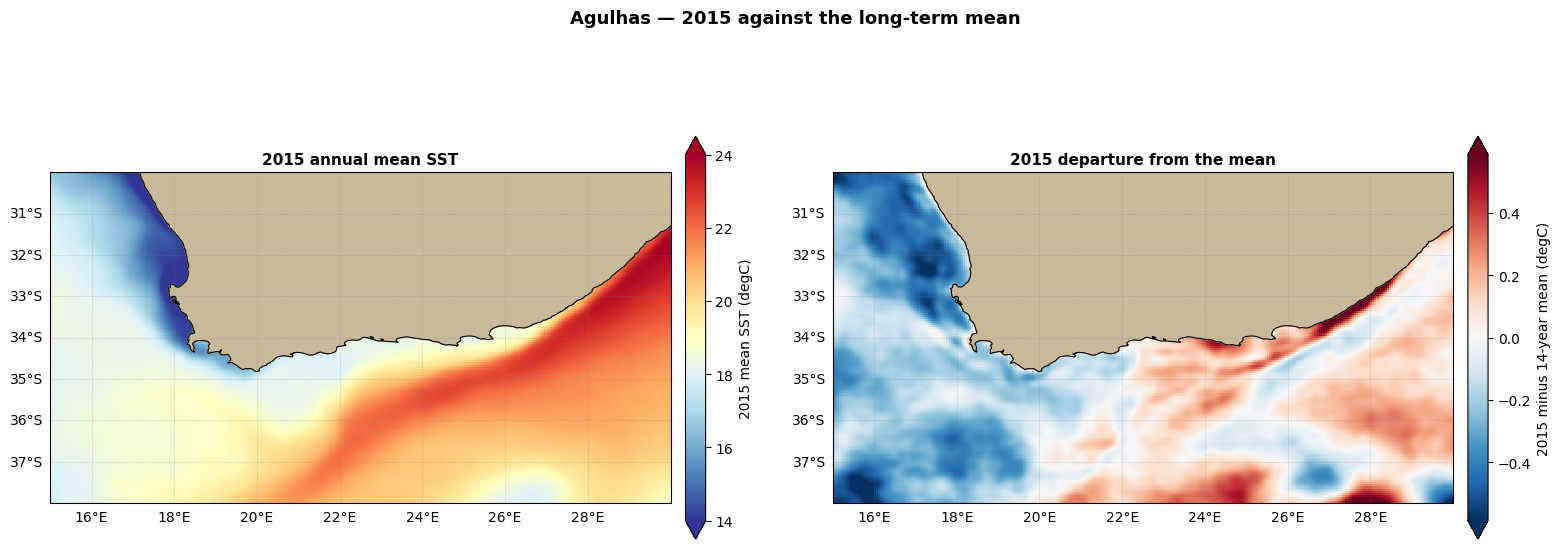

   2015 area-mean departure: -0.07 degC
   Strongest warm departure  : +1.06 degC
   Strongest cool departure  : -0.67 degC

   A fairly ordinary year for your area.


In [ ]:
# ============================================================
# 1.4 — ONE YEAR vs THE LONG-TERM MEAN
# ─────────────────────────────────────────────────────────────
# Left  : that year's mean SST
# Right : that year MINUS the 14-year mean = the anomaly
#
# Change YEAR and re-run. 2010, 2015, 2016, 2019, 2021 are all
# worth a look.
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

YEAR = 2015          # <- change me

sst_year = sst.sel(time=str(YEAR)).mean('time').compute()
diff     = sst_year - sst_mean

fig, axes = plt.subplots(1, 2, figsize=(16, 6),
                         subplot_kw={'projection': ccrs.PlateCarree()})

# --- left: that year ---
sst_year.plot(ax=axes[0], transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=SST_VMIN, vmax=SST_VMAX, extend='both',
              cbar_kwargs={'label': f'{YEAR} mean SST (degC)', 'shrink': 0.75, 'pad': 0.02},
              add_labels=False)
axes[0].set_title(f'{YEAR} annual mean SST', fontsize=11, fontweight='bold')

# --- right: the departure ---
lim = float(abs(diff).quantile(0.99))
diff.plot(ax=axes[1], transform=ccrs.PlateCarree(), cmap='RdBu_r',
          vmin=-lim, vmax=lim, extend='both',
          cbar_kwargs={'label': f'{YEAR} minus 14-year mean (degC)', 'shrink': 0.75, 'pad': 0.02},
          add_labels=False)
axes[1].set_title(f'{YEAR} departure from the mean', fontsize=11, fontweight='bold')

for ax in axes:
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False

fig.suptitle(f'{ZONE_NAME} — {YEAR} against the long-term mean',
             fontsize=13, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_SST_{YEAR}_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

d_mean = float(diff.mean())
print(f'   {YEAR} area-mean departure: {d_mean:+.2f} degC')
print(f'   Strongest warm departure  : {float(diff.max()):+.2f} degC')
print(f'   Strongest cool departure  : {float(diff.min()):+.2f} degC')
print()
if abs(d_mean) < 0.15:
    print('   A fairly ordinary year for your area.')
elif d_mean > 0:
    print('   Warmer than usual overall. Was it warm all year, or one season?')
    print('   Section 2 answers that.')
else:
    print('   Cooler than usual overall. Stronger upwelling, or a cool season?')
    print('   Section 2 answers that.')


### 1.5 — Extension: a cross-section

*Optional — if you finish early*

A map shows structure in two dimensions. Sometimes one line through the data is clearer — particularly for a coastal gradient.

---


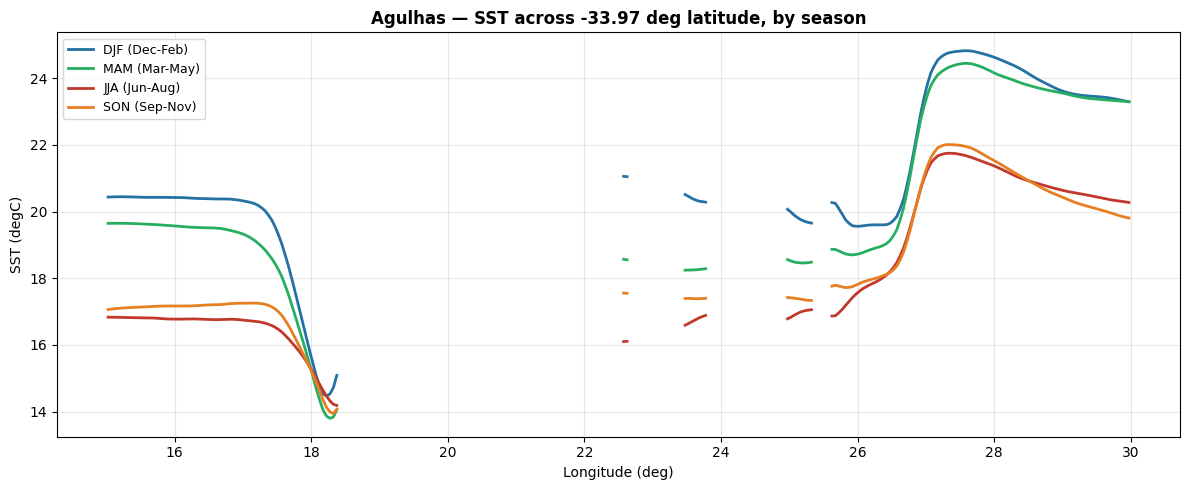

   Cross-section at -33.97 deg latitude
   Where the lines spread widest, the seasonal cycle is strongest.
   Where they converge, SST barely changes through the year.


In [ ]:
# ============================================================
# 1.5 — EXTENSION: SST ALONG A LINE
# ─────────────────────────────────────────────────────────────
# Pick a latitude and plot SST across it, one line per season.
# For a coastal upwelling area, run the line offshore from the
# coast and you should see the gradient directly.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

CROSS_LAT = (LAT_MIN + LAT_MAX) / 2      # <- change me

fig, ax = plt.subplots(figsize=(12, 5))

for season, col in zip(SEASON_ORDER, ['#2471a3', '#27ae60', '#c0392b', '#e67e22']):
    line = sst_seasonal.sel(season=season).sel(latitude=CROSS_LAT, method='nearest')
    ax.plot(line.longitude, line.values, lw=2, color=col,
            label=f'{season} ({SEASON_LABEL[season]})')

actual_lat = float(sst_seasonal.sel(latitude=CROSS_LAT, method='nearest').latitude)
ax.set_xlabel('Longitude (deg)', fontsize=10)
ax.set_ylabel('SST (degC)', fontsize=10)
ax.set_title(f'{ZONE_NAME} — SST across {actual_lat:.2f} deg latitude, by season',
             fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_SST_crosssection_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f'   Cross-section at {actual_lat:.2f} deg latitude')
print('   Where the lines spread widest, the seasonal cycle is strongest.')
print('   Where they converge, SST barely changes through the year.')


---

##  Gallery Walk — SST Maps

*Reconvergence Plenary  |  12:15–12:45  (30 min)*

One volunteer per subgroup shares a map. The Lead Instructor annotates live.

**Q1 — Which season is coolest in your area, and why?**
All three areas will probably say a cool season exists. The *mechanism* differs completely: alongshore Ekman transport in Area 1, equatorial divergence in Area 2, winter cooling in Area 3.

**Q2 — Area 3, whose season are you talking about?**
JJA is winter in the Agulhas. When three groups all say "our cool season is JJA", make sure everyone understands they do not mean the same thing.

**Q3 — How big is the seasonal range in your area?**
Read it off the seasonal panel titles. Which area swings most through the year — and does that match what you expected from the regime?

**Q4 — Was your chosen year ordinary?**
Compare the departure maps. Did anyone find a year that stands out strongly?

---


---
---

#  Section 2 — Anomaly Detection & Seasonal Averages

*Demonstration 13:45–14:30  |  Subgroup analysis 14:30–16:15*

An **anomaly** is what is left when you remove the seasonal cycle. It is the single most useful transformation in ocean data analysis, because it makes January and July comparable.

$$\text{anomaly} = \text{monthly SST} - \text{climatology for that calendar month}$$

A +1.5 degC anomaly means the same thing in either month, even though the absolute temperatures differ by several degrees.

**What you will produce:**

1. A monthly climatology — 12 fields, one per calendar month
2. Anomaly fields for the whole record
3. Anomaly maps for notable months
4. An anomaly time series for your area
5. A four-panel analysis to present at 16:30

> **MOOC connection:** Module 2 — seasonal variability and its physical drivers. Module 6 — reading variability in forecast products.

---


### 2.1 — From daily to monthly

*within Demonstration  |  13:45–14:30*

Anomalies are computed on **monthly** data. Two steps:

1. `resample(time='ME')` — daily to monthly means, about 5,100 timesteps down to 168
2. `groupby('time.month').mean()` — average all Januaries, all Februaries, and so on

Step 2 gives the **climatology**: 12 spatial fields describing the average year.

---


In [ ]:
# ============================================================
# 2.1 — MONTHLY MEANS AND THE CLIMATOLOGY
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

print('Resampling daily -> monthly...')
sst_monthly = sst.resample(time='ME').mean().compute()
print(f'   {sst.sizes["time"]} daily -> {sst_monthly.sizes["time"]} monthly timesteps')
print()

print('Computing the monthly climatology...')
sst_clim = sst_monthly.groupby('time.month').mean('time')
print(f'   Climatology shape: {sst_clim.shape}  (12 months x lat x lon)')
print()

print(f'Average year for {ZONE_NAME}:')
clim_series = [float(sst_clim.sel(month=m).mean()) for m in range(1, 13)]
lo, hi = min(clim_series), max(clim_series)
for m, val in enumerate(clim_series, start=1):
    bar = '#' * int((val - lo) / max(hi - lo, 0.01) * 40 + 1)
    mark = '  <- coolest' if val == lo else ('  <- warmest' if val == hi else '')
    print(f'   {MONTH_NAMES[m-1]}  {val:>6.2f} degC  {bar}{mark}')
print()
print(f'   Seasonal amplitude: {hi - lo:.2f} degC')
print(f'   Coolest month: {MONTH_NAMES[clim_series.index(lo)]}   '
      f'Warmest: {MONTH_NAMES[clim_series.index(hi)]}')


Resampling daily -> monthly...
   5113 daily -> 168 monthly timesteps

Computing the monthly climatology...
   Climatology shape: (12, 160, 300)  (12 months x lat x lon)

Average year for Agulhas:
   Jan   21.47 degC  #####################################
   Feb   21.88 degC  #########################################  <- warmest
   Mar   21.55 degC  #####################################
   Apr   20.44 degC  ###########################
   May   19.60 degC  ###################
   Jun   18.64 degC  ##########
   Jul   17.93 degC  ###
   Aug   17.62 degC  #  <- coolest
   Sep   17.79 degC  ##
   Oct   18.35 degC  #######
   Nov   19.23 degC  ################
   Dec   20.47 degC  ###########################

   Seasonal amplitude: 4.26 degC
   Coolest month: Aug   Warmest: Feb


### 2.2 — The climatology as twelve maps

*within Demonstration  |  13:45–14:30*

The numbers above are area averages. The maps show *where* the seasonal change happens — which is rarely uniform.

---


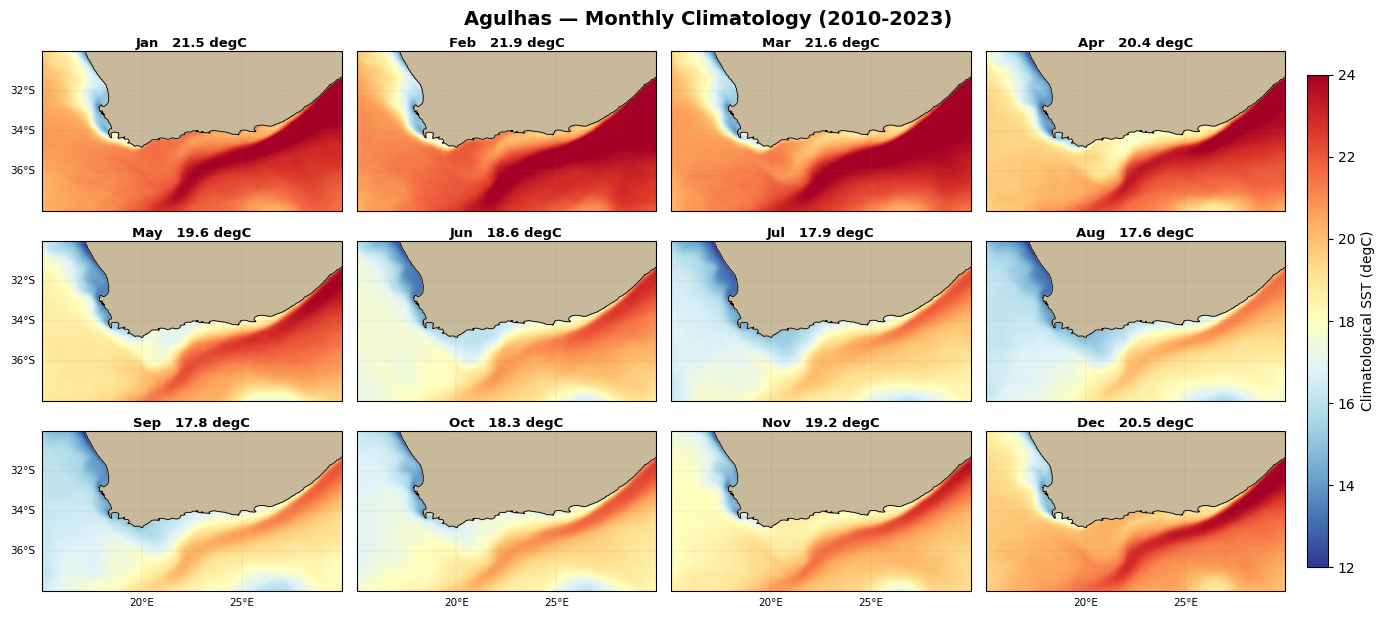

   Warmest month: Feb  21.88 degC
   Coolest month: Aug  17.62 degC
   Annual range : 4.26 degC

   Watch how the pattern moves across the twelve panels.
   Does the whole area warm and cool together, or does one
   part change while another stays put? That difference is
   usually where the interesting physics lives.


In [ ]:
# ============================================================
# 2.2 — TWELVE CLIMATOLOGY MAPS
# ─────────────────────────────────────────────────────────────
# One shared colour scale across all twelve, so the months are
# comparable. Watch which PART of your area changes most.
#
# Axis labels only on the LEFT column (latitude) and BOTTOM row
# (longitude) — twelve fully-labelled panels would be unreadable.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

NROW, NCOL = 3, 4

# ---- size the figure from the domain aspect ratio ----
aspect  = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
panel_w = 3.3
fig_w   = NCOL * panel_w + 1.6
fig_h   = NROW * panel_w / aspect + 1.2
fig_h   = min(max(fig_h, 5.0), 13.0)

fig, axes = plt.subplots(NROW, NCOL, figsize=(fig_w, fig_h),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         gridspec_kw={'wspace': 0.05, 'hspace': 0.16})

for m, ax in enumerate(axes.flat, start=1):
    row, col = divmod(m - 1, NCOL)
    field = sst_clim.sel(month=m)

    im = field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
                    vmin=SNAP_VMIN, vmax=SNAP_VMAX, extend='both',
                    add_colorbar=False, add_labels=False)

    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.6, zorder=3)

    gl = ax.gridlines(draw_labels=True, linewidth=0.35, color='gray',
                      alpha=0.35, linestyle='--')
    gl.top_labels   = False
    gl.right_labels = False
    gl.left_labels   = (col == 0)            # latitude on the first column
    gl.bottom_labels = (row == NROW - 1)     # longitude on the last row
    gl.xlocator = mticker.MaxNLocator(3)
    gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 7.5}
    gl.ylabel_style = {'size': 7.5}

    ax.set_title(f'{MONTH_NAMES[m-1]}   {float(field.mean()):.1f} degC',
                 fontsize=9.5, fontweight='bold', pad=3)

fig.subplots_adjust(left=0.05, right=0.89, top=0.90, bottom=0.06)
cax = fig.add_axes([0.905, 0.10, 0.014, 0.76])
fig.colorbar(im, cax=cax, label='Climatological SST (degC)')

fig.suptitle(f'{ZONE_NAME} — Monthly Climatology ({DATE_START[:4]}-{DATE_END[:4]})',
             fontsize=14, fontweight='bold', y=0.96)

plt.savefig(f'{OUTPUT_DIR}/Day2_climatology_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

vals = {m: float(sst_clim.sel(month=m).mean()) for m in range(1, 13)}
lo_m, hi_m = min(vals, key=vals.get), max(vals, key=vals.get)
print(f'   Warmest month: {MONTH_NAMES[hi_m-1]}  {vals[hi_m]:.2f} degC')
print(f'   Coolest month: {MONTH_NAMES[lo_m-1]}  {vals[lo_m]:.2f} degC')
print(f'   Annual range : {vals[hi_m] - vals[lo_m]:.2f} degC')
print()
print('   Watch how the pattern moves across the twelve panels.')
print('   Does the whole area warm and cool together, or does one')
print('   part change while another stays put? That difference is')
print('   usually where the interesting physics lives.')

### 2.3 — Anomaly fields

*within Demonstration  |  13:45–14:30*

Now subtract. The `groupby('time.month') - sst_clim` pattern matches each month against its own climatology automatically.

---


In [ ]:
# ============================================================
# 2.3 — COMPUTE THE ANOMALIES
# ─────────────────────────────────────────────────────────────
# anomaly = monthly SST - climatology for that calendar month
#
# groupby('time.month') aligns each timestep with the right
# month of the climatology before subtracting. Doing this by
# hand is where people usually make mistakes.
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

sst_anom = (sst_monthly.groupby('time.month') - sst_clim)
sst_anom = sst_anom.drop_vars('month', errors='ignore')

print(f'==> Anomalies computed — shape {sst_anom.shape}')
print()
print(f'   Range: {float(sst_anom.min()):+.2f} to {float(sst_anom.max()):+.2f} degC')
print()

area_anom = sst_anom.mean(['latitude', 'longitude']).to_series()

print('   Five warmest months on record for your area:')
for t, v in area_anom.nlargest(5).items():
    print(f'     {t:%Y-%m}   {v:+.2f} degC')
print()
print('   Five coolest months on record:')
for t, v in area_anom.nsmallest(5).items():
    print(f'     {t:%Y-%m}   {v:+.2f} degC')
print()
print('   Positive = warmer than usual FOR THAT MONTH.')
print('   Anomalies above about +1 degC sustained over at least 5 are')
print('   what gets called a marine heatwave.')


==> Anomalies computed — shape (168, 160, 300)

   Range: -4.36 to +4.67 degC

   Five warmest months on record for your area:
     2015-12   +1.01 degC
     2016-01   +1.00 degC
     2019-09   +0.86 degC
     2020-06   +0.83 degC
     2020-05   +0.79 degC

   Five coolest months on record:
     2017-12   -0.73 degC
     2021-12   -0.64 degC
     2018-01   -0.63 degC
     2015-03   -0.63 degC
     2018-02   -0.56 degC

   Positive = warmer than usual FOR THAT MONTH.
   Anomalies above about +1 degC sustained over at least 5 are
   what gets called a marine heatwave.


### 2.4 — Anomaly maps

*within Subgroup Analysis  |  14:30–16:15*

The warmest and coolest months from the list above, mapped. Note the diverging colour scale centred on zero — for anomalies, white must mean "normal".

---


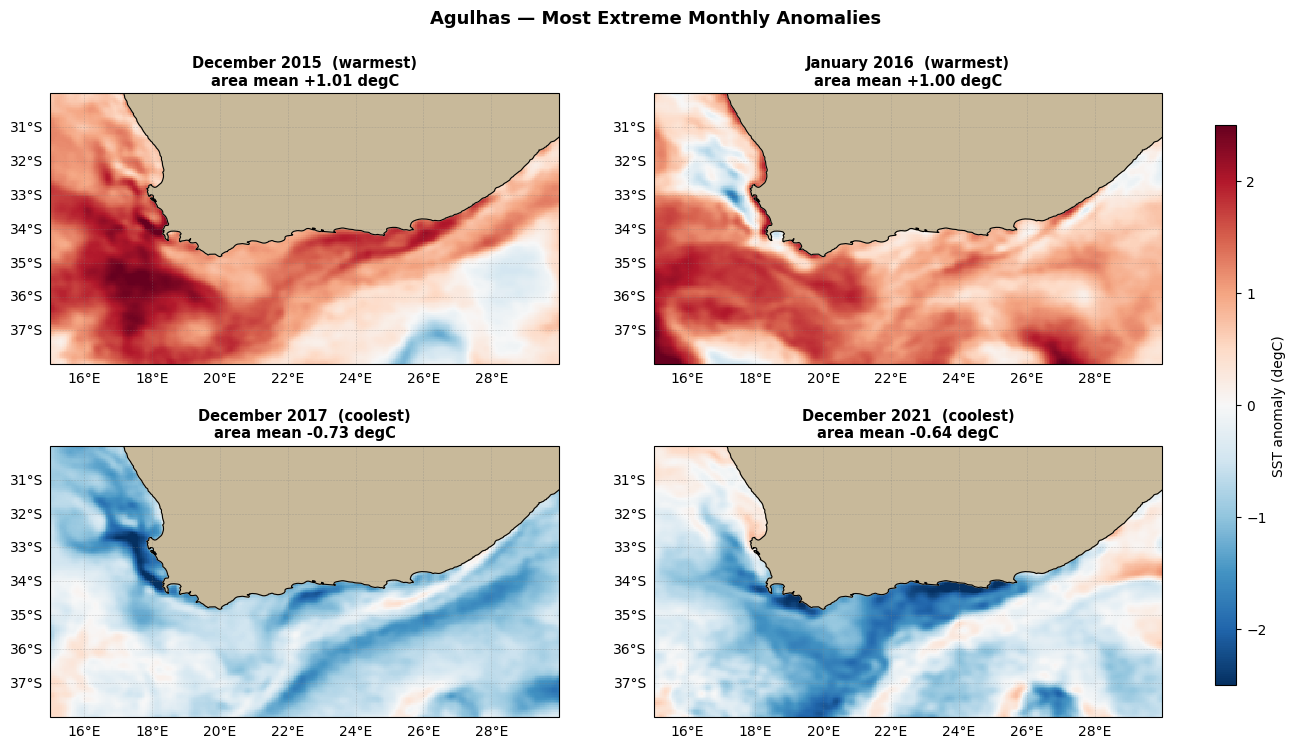

   Red = warmer than usual for that month, blue = cooler.
   Is the anomaly spread across your whole area, or concentrated
   in one part of it? A patchy anomaly and a uniform one usually
   have different causes.


In [ ]:
# ============================================================
# 2.4 — MAPS OF THE MOST EXTREME MONTHS
# ─────────────────────────────────────────────────────────────
# Diverging colormap, symmetric about zero. This is not a
# style choice: for an anomaly, the eye must be able to find
# "no departure" instantly, and that has to be the midpoint.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

warm_dates = list(area_anom.nlargest(2).index)
cool_dates = list(area_anom.nsmallest(2).index)
picks = [(d, 'warmest') for d in warm_dates] + [(d, 'coolest') for d in cool_dates]

fig, axes = plt.subplots(2, 2, figsize=(14, 8),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         gridspec_kw={'wspace': 0.08, 'hspace': 0.30})

for ax, (date, kind) in zip(axes.flat, picks):
    field = sst_anom.sel(time=date, method='nearest')
    im = field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
                    vmin=-ANOM_LIM, vmax=ANOM_LIM, extend='both',
                    add_colorbar=False, add_labels=False)
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    ax.set_title(f'{date:%B %Y}  ({kind})\narea mean {float(field.mean()):+.2f} degC',
                 fontsize=10.5, fontweight='bold')

fig.subplots_adjust(left=0.05, right=0.88, top=0.86, bottom=0.08)
cax = fig.add_axes([0.90, 0.12, 0.015, 0.70])
fig.colorbar(im, cax=cax, label='SST anomaly (degC)')

fig.suptitle(f'{ZONE_NAME} — Most Extreme Monthly Anomalies',
             fontsize=13, fontweight='bold', y=0.965)

plt.savefig(f'{OUTPUT_DIR}/Day2_anomaly_maps_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('   Red = warmer than usual for that month, blue = cooler.')
print('   Is the anomaly spread across your whole area, or concentrated')
print('   in one part of it? A patchy anomaly and a uniform one usually')
print('   have different causes.')


### 2.5 — The anomaly time series

*within Subgroup Analysis  |  14:30–16:15*

Fourteen years of departures, in one line. This is the figure your subgroup will present.

---


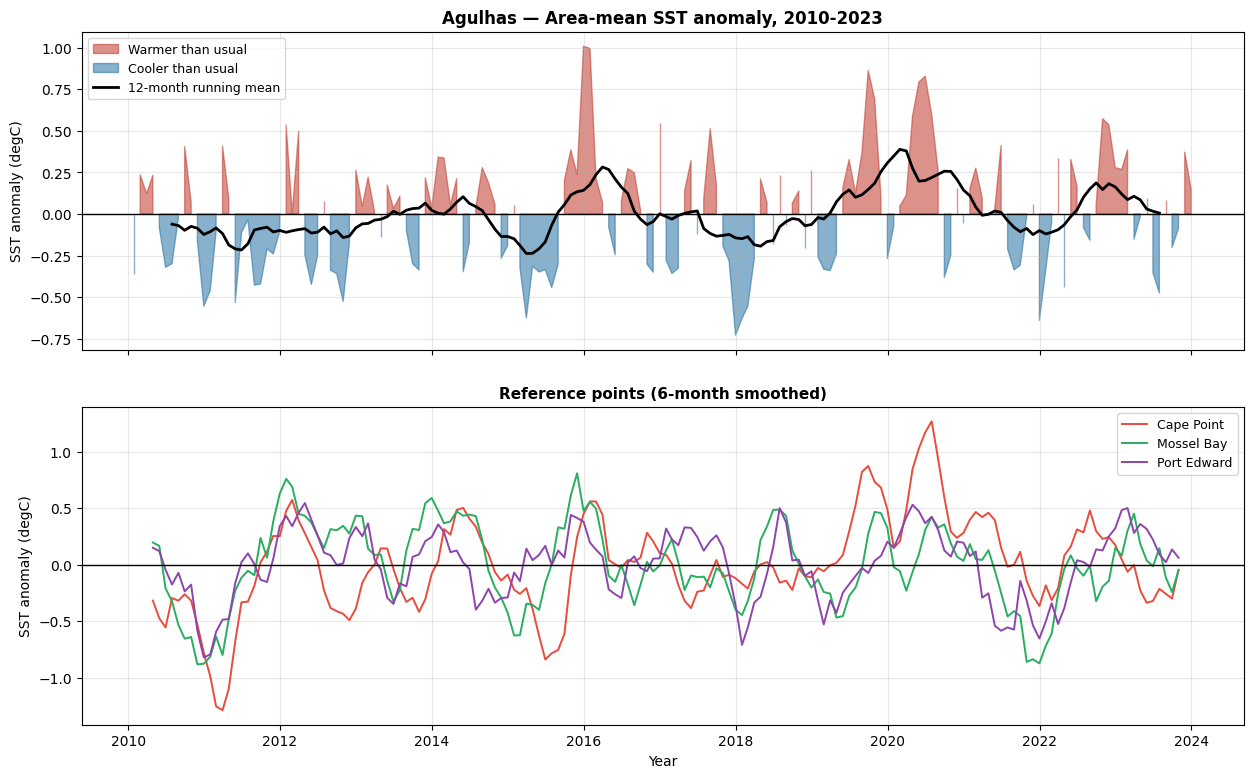

   Mean anomaly 2010-2015 : -0.057 degC
   Mean anomaly 2018-2023 : +0.052 degC
   Difference             : +0.109 degC

   The later period is warmer. Careful: 14 years is short for a
   climate trend, and this could be decadal variability. Say so.


In [ ]:
# ============================================================
# 2.5 — ANOMALY TIME SERIES FOR YOUR AREA
# ─────────────────────────────────────────────────────────────
# Red above zero, blue below. The 12-month running mean strips
# out month-to-month noise and shows the slower swings.
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

roll = area_anom.rolling(12, center=True).mean()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), sharex=True,
                               gridspec_kw={'hspace': 0.18})

# --- upper: area-mean anomaly ---
ax1.fill_between(area_anom.index, 0, area_anom.values,
                 where=area_anom.values >= 0, color='#c0392b', alpha=0.55,
                 label='Warmer than usual')
ax1.fill_between(area_anom.index, 0, area_anom.values,
                 where=area_anom.values < 0, color='#2471a3', alpha=0.55,
                 label='Cooler than usual')
ax1.plot(roll.index, roll.values, color='black', lw=2,
         label='12-month running mean')
ax1.axhline(0, color='black', lw=1)
ax1.set_ylabel('SST anomaly (degC)', fontsize=10)
ax1.set_title(f'{ZONE_NAME} — Area-mean SST anomaly, {DATE_START[:4]}-{DATE_END[:4]}',
              fontsize=12, fontweight='bold')
ax1.legend(fontsize=9, loc='upper left'); ax1.grid(True, alpha=0.3)

# --- lower: the three reference points ---
for (lon, lat, label), col in zip(REF_POINTS, COLORS):
    pt   = sst_anom.sel(longitude=lon, latitude=lat, method='nearest')
    ser  = pt.to_series().rolling(6, center=True).mean()
    name = label.split('(')[0].strip()
    ax2.plot(ser.index, ser.values, color=col, lw=1.4, label=name)

ax2.axhline(0, color='black', lw=1)
ax2.set_ylabel('SST anomaly (degC)', fontsize=10)
ax2.set_xlabel('Year', fontsize=10)
ax2.set_title('Reference points (6-month smoothed)', fontsize=11, fontweight='bold')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

plt.savefig(f'{OUTPUT_DIR}/Day2_anomaly_timeseries_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

early = area_anom['2010':'2015'].mean()
late  = area_anom['2018':'2023'].mean()
print(f'   Mean anomaly 2010-2015 : {early:+.3f} degC')
print(f'   Mean anomaly 2018-2023 : {late:+.3f} degC')
print(f'   Difference             : {late - early:+.3f} degC')
print()
if late - early > 0.1:
    print('   The later period is warmer. Careful: 14 years is short for a')
    print('   climate trend, and this could be decadal variability. Say so.')
elif late - early < -0.1:
    print('   The later period is cooler — worth investigating rather than')
    print('   assuming an error.')
else:
    print('   No clear shift between the two periods in your area.')


### 2.6 — Your subgroup analysis

*within Subgroup Analysis  |  14:30–16:15*

The four panels you present at 16:30. Run it, read it, and decide what your area's story is.

---


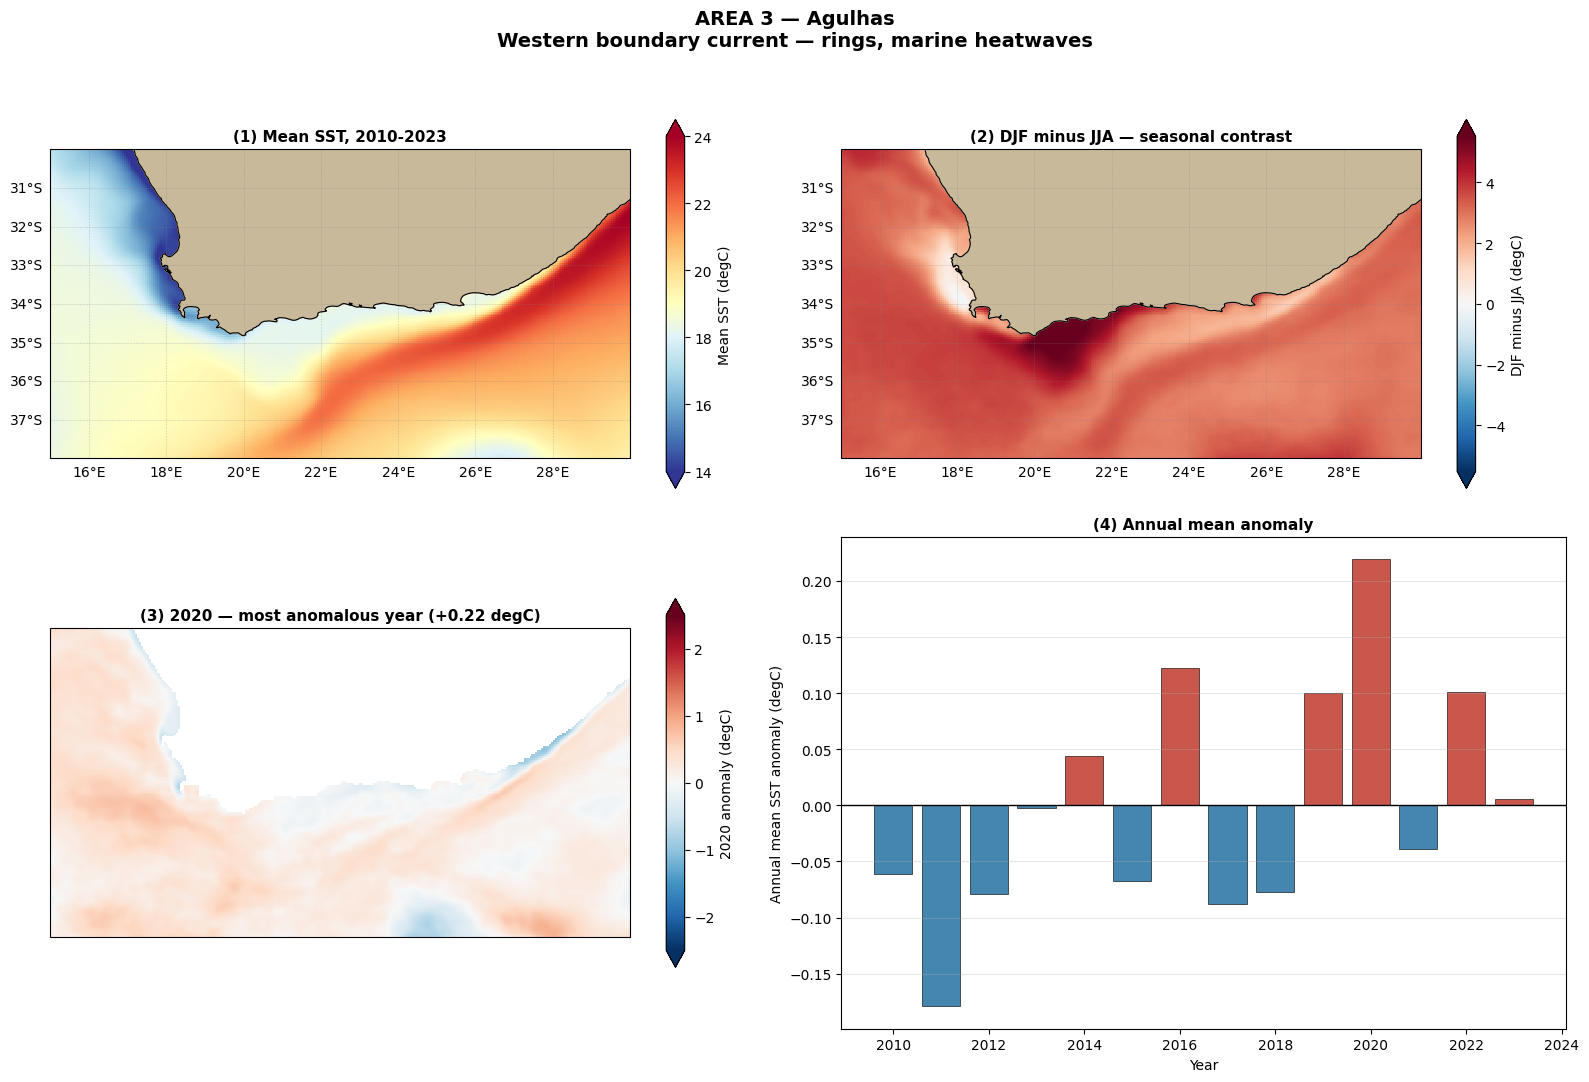

   AREA 3 — Agulhas
   Mean SST                : 19.57 degC
   Seasonal amplitude      : 4.26 degC
   Cool season             : DJF
   Most anomalous year     : 2020  (+0.22 degC)
   Warmest month on record : 2015-12  (+1.01 degC)
   Coolest month on record : 2017-12  (-0.73 degC)

   Take these numbers to the plenary. The other two areas will
   have different ones, and the differences are the discussion.


In [ ]:
# ============================================================
# 2.6 — FOUR-PANEL SUBGROUP ANALYSIS
# ─────────────────────────────────────────────────────────────
#   1  mean SST                     — the baseline pattern
#   2  cool season minus warm       — where the seasons bite
#   3  anomaly in the extreme year  — what an unusual year looks like
#   4  annual mean anomaly          — year-to-year variability
#
# SUBGROUP OUTPUT: save this figure and bring 2-3 slides.
# ============================================================
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

annual  = area_anom.resample('YE').mean()
pk_year = int(annual.abs().idxmax().year)
pk_val  = float(annual.loc[annual.abs().idxmax()])

warm_s = 'DJF' if Z['hemisphere'] == 'N' else 'JJA'
cool_s = Z['upwell_season']

fig = plt.figure(figsize=(16, 11))

# --- 1: mean SST ---
ax = fig.add_subplot(2, 2, 1, projection=ccrs.PlateCarree())
sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=SST_VMIN, vmax=SST_VMAX, extend='both',
              cbar_kwargs={'label': 'Mean SST (degC)', 'shrink': 0.75},
              add_labels=False)
ax.set_title(f'(1) Mean SST, {DATE_START[:4]}-{DATE_END[:4]}',
             fontsize=11, fontweight='bold')

# --- 2: seasonal contrast ---
ax = fig.add_subplot(2, 2, 2, projection=ccrs.PlateCarree())
contrast = sst_seasonal.sel(season=cool_s) - sst_seasonal.sel(season=warm_s)
clim_lim = float(abs(contrast).quantile(0.99))
contrast.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
              vmin=-clim_lim, vmax=clim_lim, extend='both',
              cbar_kwargs={'label': f'{cool_s} minus {warm_s} (degC)', 'shrink': 0.75},
              add_labels=False)
ax.set_title(f'(2) {cool_s} minus {warm_s} — seasonal contrast',
             fontsize=11, fontweight='bold')

# --- 3: the extreme year ---
ax = fig.add_subplot(2, 2, 3, projection=ccrs.PlateCarree())
yr_anom = sst_anom.sel(time=str(pk_year)).mean('time')
yr_anom.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
             vmin=-ANOM_LIM, vmax=ANOM_LIM, extend='both',
             cbar_kwargs={'label': f'{pk_year} anomaly (degC)', 'shrink': 0.75},
             add_labels=False)
ax.set_title(f'(3) {pk_year} — most anomalous year ({pk_val:+.2f} degC)',
             fontsize=11, fontweight='bold')

for a in fig.axes[:3]:
    if hasattr(a, 'add_feature'):
        a.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
        a.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
        gl = a.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                         alpha=0.4, linestyle='--')
        gl.top_labels = False; gl.right_labels = False

# --- 4: annual anomalies ---
ax = fig.add_subplot(2, 2, 4)
cols = ['#c0392b' if v >= 0 else '#2471a3' for v in annual.values]
ax.bar(annual.index.year, annual.values, color=cols, alpha=0.85,
       edgecolor='black', linewidth=0.5)
ax.axhline(0, color='black', lw=1)
ax.set_xlabel('Year', fontsize=10)
ax.set_ylabel('Annual mean SST anomaly (degC)', fontsize=10)
ax.set_title('(4) Annual mean anomaly', fontsize=11, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')

fig.suptitle(f'AREA {ACTIVE_ZONE} — {ZONE_NAME}\n{Z["regime"]}',
             fontsize=14, fontweight='bold', y=0.98)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_subgroup_analysis_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print('=' * 62)
print(f'   AREA {ACTIVE_ZONE} — {ZONE_NAME}')
print('=' * 62)
print(f'   Mean SST                : {float(sst_mean.mean()):.2f} degC')
print(f'   Seasonal amplitude      : {hi - lo:.2f} degC')
print(f'   Cool season             : {cool_s}')
print(f'   Most anomalous year     : {pk_year}  ({pk_val:+.2f} degC)')
print(f'   Warmest month on record : {area_anom.idxmax():%Y-%m}  '
      f'({area_anom.max():+.2f} degC)')
print(f'   Coolest month on record : {area_anom.idxmin():%Y-%m}  '
      f'({area_anom.min():+.2f} degC)')
print('=' * 62)
print()
print('   Take these numbers to the plenary. The other two areas will')
print('   have different ones, and the differences are the discussion.')


### 2.7 — Extension: does the wind explain it?

*Optional — if you finish early*

You have the anomalies. You also have the wind. Do they move together?

For Areas 1 and 2, stronger wind should mean stronger upwelling and cooler water — a negative relationship. For Area 3, the Agulhas is inertial, so the connection should be weak. **A weak correlation is a real result, not a failure.**

---


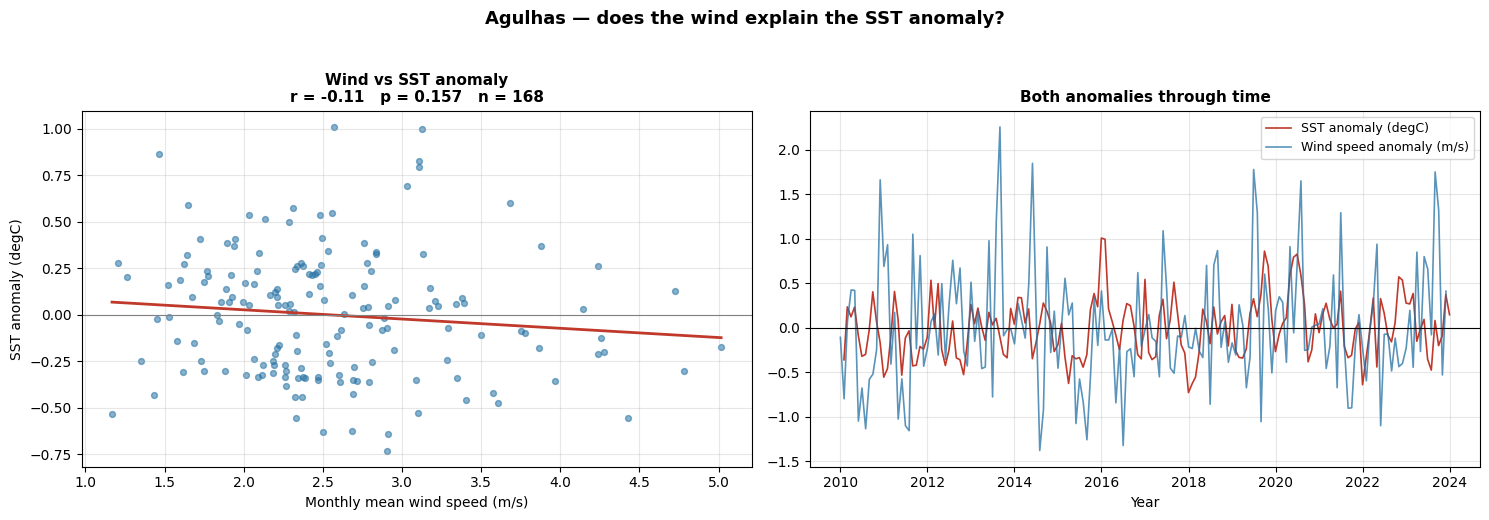

   Correlation r = -0.110   (p = 0.157, n = 168)

   Not statistically significant. In your area, monthly wind speed
   alone does not explain the SST anomaly — which is itself worth
   reporting. Other drivers matter more here.

   Remember: r measures association, not cause. And 14 years is
   short. State the limitation when you present this.


In [ ]:
# ============================================================
# 2.7 — EXTENSION: WIND SPEED vs SST ANOMALY
# ─────────────────────────────────────────────────────────────
# Wind is monthly, SST anomaly is monthly. Align them and see
# whether they move together.
#
# CAUTION: correlation is not causation, and 168 months is not
# a large sample. Treat this as a hypothesis, not a finding.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import scipy.stats as stats

ds_wind = open_product('WIND', verbose=False)

if 'u10' in ds_wind.variables:
    u, v = ds_wind['u10'], ds_wind['v10']
else:
    u, v = ds_wind['eastward_wind'], ds_wind['northward_wind']

latn = 'latitude' if 'latitude' in ds_wind.coords else 'lat'
if ds_wind[latn].size > 1 and ds_wind[latn][0] > ds_wind[latn][-1]:
    u, v = u.sortby(latn), v.sortby(latn)

wind_speed = ((u**2 + v**2)**0.5).sel(
    latitude=slice(LAT_MIN, LAT_MAX), longitude=slice(LON_MIN, LON_MAX)
).mean(['latitude', 'longitude']).to_series()

# align the two monthly series on year-month
w = wind_speed.groupby([wind_speed.index.year, wind_speed.index.month]).mean()
a = area_anom.groupby([area_anom.index.year, area_anom.index.month]).mean()
both = pd.DataFrame({'wind': w, 'anom': a}).dropna()

r, p = stats.pearsonr(both['wind'], both['anom'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

ax1.scatter(both['wind'], both['anom'], s=18, alpha=0.55, color='#2471a3')
m, b = np.polyfit(both['wind'], both['anom'], 1)
xs = np.linspace(both['wind'].min(), both['wind'].max(), 50)
ax1.plot(xs, m * xs + b, color='#c0392b', lw=2)
ax1.axhline(0, color='gray', lw=0.8)
ax1.set_xlabel('Monthly mean wind speed (m/s)', fontsize=10)
ax1.set_ylabel('SST anomaly (degC)', fontsize=10)
ax1.set_title(f'Wind vs SST anomaly\nr = {r:+.2f}   p = {p:.3g}   n = {len(both)}',
              fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3)

wc = (wind_speed - wind_speed.groupby(wind_speed.index.month).transform('mean'))
ax2.plot(area_anom.index, area_anom.values, color='#c0392b', lw=1.2,
         label='SST anomaly (degC)')
ax2.plot(wc.index, wc.values, color='#2471a3', lw=1.2, alpha=0.75,
         label='Wind speed anomaly (m/s)')
ax2.axhline(0, color='black', lw=0.8)
ax2.set_xlabel('Year', fontsize=10)
ax2.set_title('Both anomalies through time', fontsize=11, fontweight='bold')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

fig.suptitle(f'{ZONE_NAME} — does the wind explain the SST anomaly?',
             fontsize=13, fontweight='bold', y=1.03)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_wind_vs_anomaly_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f'   Correlation r = {r:+.3f}   (p = {p:.3g}, n = {len(both)})')
print()
if p > 0.05:
    print('   Not statistically significant. In your area, monthly wind speed')
    print('   alone does not explain the SST anomaly — which is itself worth')
    print('   reporting. Other drivers matter more here.')
elif r < 0:
    print('   Negative and significant: stronger wind goes with cooler water.')
    print('   Consistent with wind-driven upwelling. But note that wind SPEED')
    print('   ignores DIRECTION, and for upwelling direction is what counts.')
else:
    print('   Positive and significant: stronger wind goes with warmer water.')
    print('   Unexpected for an upwelling system — worth thinking about.')
print()
print('   Remember: r measures association, not cause. And 14 years is')
print('   short. State the limitation when you present this.')
ds_wind.close()


Computing daily area-mean SST...
   5113 days, 2010-01-01 to 2023-12-31

==> 38 marine heatwaves detected (>= 5 days above the 90th percentile)

   Ten longest events:
   start        end          days   peak intensity   mean intensity
   2019-08-22   2019-10-21     61         1.19 degC         0.81 degC
   2015-12-02   2016-01-15     45         2.16 degC         1.13 degC
   2020-05-30   2020-07-12     44         1.25 degC         0.79 degC
   2020-04-15   2020-05-26     42         1.05 degC         0.88 degC
   2017-07-29   2017-08-22     25         0.73 degC         0.60 degC
   2020-07-17   2020-08-10     25         1.00 degC         0.67 degC
   2022-11-04   2022-11-24     21         0.84 degC         0.63 degC
   2011-03-20   2011-04-06     18         0.72 degC         0.52 degC
   2022-05-12   2022-05-27     16         0.68 degC         0.48 degC
   2010-09-01   2010-09-15     15         0.60 degC         0.53 degC

   MHW days per year:
     2010    23 days  ###################

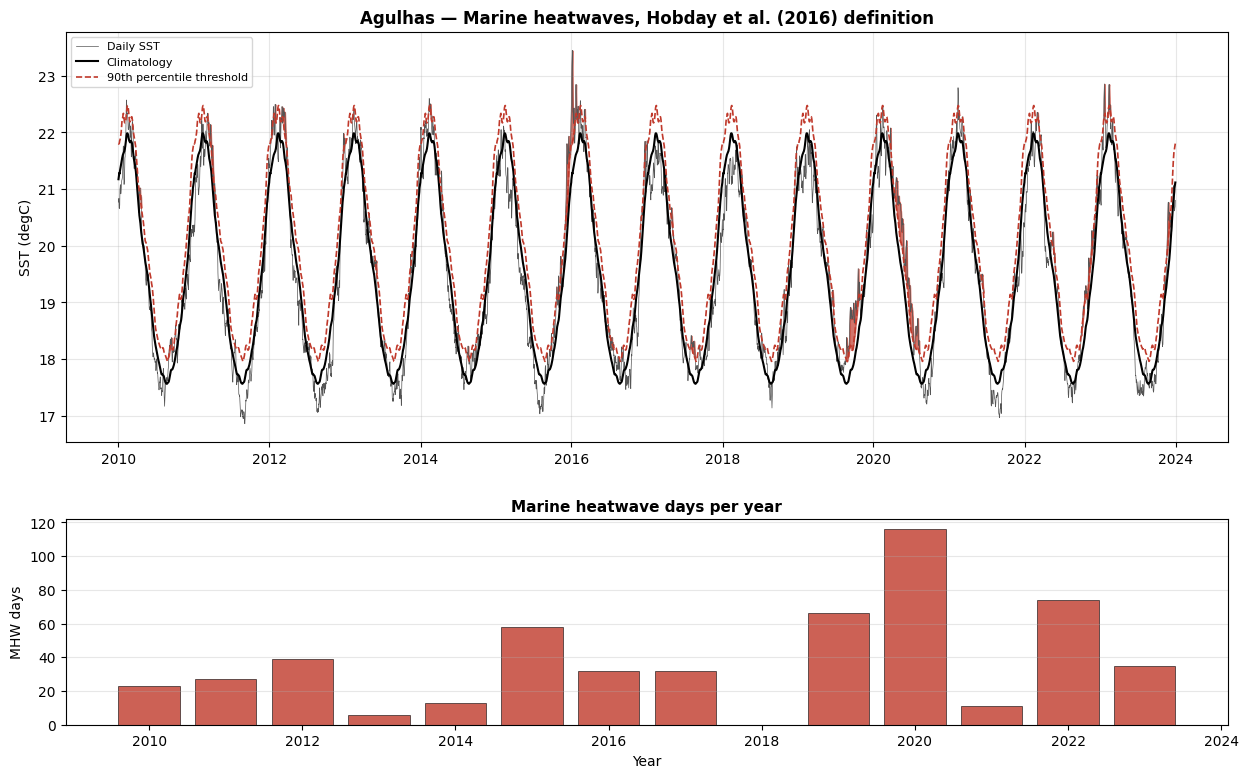


   Questions for the plenary:
   • Are MHW days increasing through the record?
   • Does your longest event coincide with the other areas?
   • What would a 20-day MHW mean for fisheries on your coast?

   CAVEAT: the standard uses a 30-year baseline (1983-2012).
   We have 14 years, so our climatology sits in a warmer period
   and this will UNDERCOUNT events relative to published figures.


In [ ]:
# ============================================================
# 2.8 — MARINE HEATWAVE DETECTION  (Hobday et al. 2016)
# ─────────────────────────────────────────────────────────────
# A marine heatwave is defined by three rules:
#   1. SST above the 90th percentile of the climatology
#      FOR THAT DAY OF YEAR  (seasonally varying threshold)
#   2. sustained for at least 5 consecutive days
#   3. gaps of 2 days or fewer join two events into one
#
# Note this uses DAILY data, not monthly — a 5-day event is
# invisible in monthly means. This is why the daily record
# was worth downloading.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

# ---- 1. area-mean daily SST ----
print('Computing daily area-mean SST...')
daily = sst.mean(['latitude', 'longitude']).to_series()
print(f'   {len(daily)} days, {daily.index[0]:%Y-%m-%d} to {daily.index[-1]:%Y-%m-%d}\n')

doy = daily.index.dayofyear

# ---- 2. seasonally varying climatology and 90th percentile ----
# Smoothed with an 11-day window so single odd days do not
# create spikes in the threshold itself.
clim_doy = daily.groupby(doy).mean()
p90_doy  = daily.groupby(doy).quantile(0.90)

def smooth_cyclic(s, window=11):
    """Rolling mean that wraps around 31 Dec / 1 Jan."""
    ext = pd.concat([s.iloc[-window:], s, s.iloc[:window]])
    return ext.rolling(window, center=True, min_periods=1).mean().iloc[window:-window]

clim_s = smooth_cyclic(clim_doy)
p90_s  = smooth_cyclic(p90_doy)

clim_line = pd.Series(doy, index=daily.index).map(clim_s)
p90_line  = pd.Series(doy, index=daily.index).map(p90_s)

# ---- 3. find events ----
above = (daily > p90_line).values
events, start = [], None
for i, hot in enumerate(above):
    if hot and start is None:
        start = i
    elif not hot and start is not None:
        events.append((start, i - 1)); start = None
if start is not None:
    events.append((start, len(above) - 1))

# join events separated by <= 2 days
joined = []
for ev in events:
    if joined and ev[0] - joined[-1][1] <= 3:
        joined[-1] = (joined[-1][0], ev[1])
    else:
        joined.append(ev)

# keep only those lasting >= 5 days
mhw = [(a, b) for a, b in joined if (b - a + 1) >= 5]

print(f'==> {len(mhw)} marine heatwaves detected (>= 5 days above the 90th percentile)\n')

rows = []
for a, b in mhw:
    seg = daily.iloc[a:b+1]
    rows.append(dict(
        start    = daily.index[a],
        end      = daily.index[b],
        days     = b - a + 1,
        peak     = float((seg - clim_line.iloc[a:b+1]).max()),
        mean_int = float((seg - clim_line.iloc[a:b+1]).mean()),
    ))
mhw_df = pd.DataFrame(rows)

if len(mhw_df):
    print('   Ten longest events:')
    print('   start        end          days   peak intensity   mean intensity')
    for _, r in mhw_df.nlargest(10, 'days').iterrows():
        print(f'   {r["start"]:%Y-%m-%d}   {r["end"]:%Y-%m-%d}   {r["days"]:>4}   '
              f'{r["peak"]:>10.2f} degC   {r["mean_int"]:>10.2f} degC')
    print()
    per_year = mhw_df.groupby(mhw_df['start'].dt.year)['days'].sum()
    print('   MHW days per year:')
    for yr in range(int(daily.index.year.min()), int(daily.index.year.max()) + 1):
        d = int(per_year.get(yr, 0))
        print(f'     {yr}   {d:>3} days  {"#" * d}')

# ---- 4. plot ----
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9),
                               gridspec_kw={'height_ratios': [2, 1], 'hspace': 0.25})

ax1.plot(daily.index, daily.values, color='#555555', lw=0.5, label='Daily SST')
ax1.plot(clim_line.index, clim_line.values, color='black', lw=1.5, label='Climatology')
ax1.plot(p90_line.index, p90_line.values, color='#c0392b', lw=1.2, ls='--',
         label='90th percentile threshold')
for a, b in mhw:
    ax1.fill_between(daily.index[a:b+1], p90_line.iloc[a:b+1], daily.iloc[a:b+1],
                     color='#c0392b', alpha=0.7)
ax1.set_ylabel('SST (degC)', fontsize=10)
ax1.set_title(f'{ZONE_NAME} — Marine heatwaves, Hobday et al. (2016) definition',
              fontsize=12, fontweight='bold')
ax1.legend(fontsize=8, loc='upper left'); ax1.grid(True, alpha=0.3)

if len(mhw_df):
    yrs = range(int(daily.index.year.min()), int(daily.index.year.max()) + 1)
    ax2.bar(list(yrs), [int(per_year.get(y, 0)) for y in yrs],
            color='#c0392b', alpha=0.8, edgecolor='black', linewidth=0.5)
ax2.set_xlabel('Year', fontsize=10)
ax2.set_ylabel('MHW days', fontsize=10)
ax2.set_title('Marine heatwave days per year', fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')

plt.savefig(f'{OUTPUT_DIR}/Day2_marine_heatwaves_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print()
print('   Questions for the plenary:')
print('   • Are MHW days increasing through the record?')
print('   • Does your longest event coincide with the other areas?')
print('   • What would a 20-day MHW mean for fisheries on your coast?')
print()
print('   CAVEAT: the standard uses a 30-year baseline (1983-2012).')
print('   We have 14 years, so our climatology sits in a warmer period')
print('   and this will UNDERCOUNT events relative to published figures.')

Grid coarsened 4x -> 40 x 75 points
Loading into memory (slow step)...
Done.

Computing per-pixel thresholds...
Done.

Applying the duration rule at every grid point...
Done.



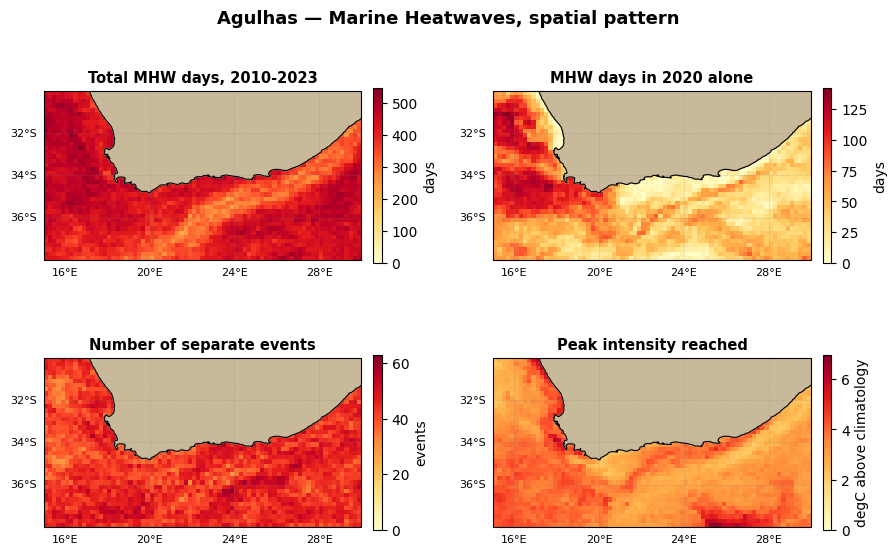

   Total MHW days      : min 0, mean 269, max 548
   2020 MHW days       : min 0, mean 35, max 142
   Separate events     : min 0, max 63
   Peak intensity      : max 6.97 degC

   The area is NOT uniformly affected — a 548-day spread
   across the domain. Which part suffers most, and why?

   The area mean in 2.8 hid this. Always ask whether an area
   average is describing everywhere or nowhere.

   FOR THE PLENARY
   Panel 2 shows 2020, the notable year for your area. Ask the
   other two subgroups which year theirs was. Different years means
   regional drivers; a shared year means something larger was at work.


In [ ]:
# ============================================================
# 2.9 — MARINE HEATWAVE MAPS — WHERE, NOT JUST WHEN
# ─────────────────────────────────────────────────────────────
# Cell 2.8 detected heatwaves in the AREA MEAN. That hides the
# spatial story: 255 days averaged could be 365 days over half
# the domain and 145 over the other half.
#
# Here we run the same Hobday test at EVERY grid point.
#
# SET FOCUS_YEAR to the notable year for YOUR area. Panel 2 and
# its title follow automatically.
#     Area 1  Mauritania / Senegal  -> 2023
#     Area 2  Gulf of Guinea        -> 2019
#     Area 3  Agulhas               -> check your own record
#
# COST: this is the slowest cell in the notebook. It applies a
# per-pixel algorithm to a 3-D array. Coarsening first keeps it
# to a few minutes instead of half an hour.
# ============================================================

import warnings
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

COARSEN    = 4          # average 4x4 grid cells first. 1 = full resolution (slow)
MIN_DAYS   = 5          # Hobday duration rule
FOCUS_YEAR = 2020       # <- the year shown in panel 2. Change per area.

sst_c = sst.coarsen(latitude=COARSEN, longitude=COARSEN,
                    boundary='trim').mean()
print(f'Grid coarsened {COARSEN}x -> {sst_c.shape[1]} x {sst_c.shape[2]} points')
print('Loading into memory (slow step)...')
arr = sst_c.compute()
print('Done.\n')

doy   = arr.time.dt.dayofyear.values
years = arr.time.dt.year.values
uy    = np.unique(years)

if FOCUS_YEAR not in uy:
    print(f'!! FOCUS_YEAR {FOCUS_YEAR} is outside the record '
          f'({uy.min()}-{uy.max()}). Panel 2 will be empty.')
    print()

# ---- per-pixel climatology and 90th percentile by day of year ----
print('Computing per-pixel thresholds...')
clim_map = arr.groupby('time.dayofyear').mean('time')
p90_map  = arr.groupby('time.dayofyear').quantile(0.90, dim='time')

def smooth_map(da, window=11):
    """Cyclic rolling mean over day-of-year, wrapping 31 Dec into 1 Jan."""
    ext = xr.concat([da.isel(dayofyear=slice(-window, None)),
                     da,
                     da.isel(dayofyear=slice(0, window))], dim='dayofyear')
    sm = ext.rolling(dayofyear=window, center=True, min_periods=1).mean()
    return sm.isel(dayofyear=slice(window, window + da.sizes['dayofyear']))

clim_s = smooth_map(clim_map)
p90_s  = smooth_map(p90_map)

thresh = p90_s.sel(dayofyear=xr.DataArray(doy, dims='time')).values
climd  = clim_s.sel(dayofyear=xr.DataArray(doy, dims='time')).values
above  = arr.values > thresh
print('Done.\n')

# ---- apply the 5-day rule along the time axis, per pixel ----
print('Applying the duration rule at every grid point...')
nt, ny, nx = above.shape
mhw_days  = np.zeros((ny, nx))
mhw_focus = np.zeros((ny, nx))
mhw_count = np.zeros((ny, nx))
peak_int  = np.zeros((ny, nx))

for j in range(ny):
    for i in range(nx):
        col = above[:, j, i]
        if not col.any():
            continue
        # run-length encode the True stretches
        d = np.diff(np.concatenate(([0], col.view(np.int8), [0])))
        starts = np.where(d == 1)[0]
        ends   = np.where(d == -1)[0] - 1
        keep   = (ends - starts + 1) >= MIN_DAYS
        starts, ends = starts[keep], ends[keep]
        if len(starts) == 0:
            continue
        mhw_count[j, i] = len(starts)
        for a, b in zip(starts, ends):
            mhw_days[j, i]  += b - a + 1
            yr_slice = years[a:b+1]
            mhw_focus[j, i] += np.sum(yr_slice == FOCUS_YEAR)
            inten = (arr.values[a:b+1, j, i] - climd[a:b+1, j, i]).max()
            peak_int[j, i] = max(peak_int[j, i], inten)
print('Done.\n')

coords = dict(latitude=arr.latitude, longitude=arr.longitude)
dims   = ('latitude', 'longitude')
m_days  = xr.DataArray(mhw_days,  coords=coords, dims=dims)
m_focus = xr.DataArray(mhw_focus, coords=coords, dims=dims)
m_count = xr.DataArray(mhw_count, coords=coords, dims=dims)
m_peak  = xr.DataArray(peak_int,  coords=coords, dims=dims)

# ---- plot ----
aspect  = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
panel_w = 4.6
fig_w   = 2 * panel_w + 1.6
fig_h   = min(max(2 * panel_w / aspect + 1.4, 6.0), 13.0)

fig, axes = plt.subplots(2, 2, figsize=(fig_w, fig_h),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         gridspec_kw={'wspace': 0.16, 'hspace': 0.22})

panels = [
    (m_days,  f'Total MHW days, {DATE_START[:4]}-{DATE_END[:4]}', 'days'),
    (m_focus, f'MHW days in {FOCUS_YEAR} alone',                  'days'),
    (m_count, 'Number of separate events',                        'events'),
    (m_peak,  'Peak intensity reached',            'degC above climatology'),
]

for ax, (field, title, unit) in zip(axes.flat, panels):
    field.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='YlOrRd',
               cbar_kwargs={'label': unit, 'shrink': 0.8, 'pad': 0.03},
               add_labels=False)
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    gl.xlocator = mticker.MaxNLocator(4); gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}
    ax.set_title(title, fontsize=10.5, fontweight='bold')

fig.suptitle(f'{ZONE_NAME} — Marine Heatwaves, spatial pattern',
             fontsize=13, fontweight='bold', y=0.97)

plt.savefig(f'{OUTPUT_DIR}/Day2_MHW_maps_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f'   Total MHW days      : min {float(m_days.min()):.0f}, '
      f'mean {float(m_days.mean()):.0f}, max {float(m_days.max()):.0f}')
print(f'   {FOCUS_YEAR} MHW days       : min {float(m_focus.min()):.0f}, '
      f'mean {float(m_focus.mean()):.0f}, max {float(m_focus.max()):.0f}')
print(f'   Separate events     : min {float(m_count.min()):.0f}, '
      f'max {float(m_count.max()):.0f}')
print(f'   Peak intensity      : max {float(m_peak.max()):.2f} degC')
print()

spread = float(m_days.max() - m_days.min())
if spread > 100:
    print(f'   The area is NOT uniformly affected — a {spread:.0f}-day spread')
    print('   across the domain. Which part suffers most, and why?')
else:
    print('   Fairly uniform across the area.')
print()
print('   The area mean in 2.8 hid this. Always ask whether an area')
print('   average is describing everywhere or nowhere.')
print()
print('   FOR THE PLENARY')
print(f'   Panel 2 shows {FOCUS_YEAR}, the notable year for your area. Ask the')
print('   other two subgroups which year theirs was. Different years means')
print('   regional drivers; a shared year means something larger was at work.')

AREA-MEAN TREND
   slope      : +0.129 degC per decade
   p-value    : 0.04248
   r-squared  : 0.025
   std error  : 0.063 degC/decade
   total rise : +0.18 degC over 14 years

   Statistically significant at p < 0.05.

   First 3 years mean anomaly : -0.106 degC
   Last  3 years mean anomaly : +0.022 degC
   If the record begins in a cool spell and ends in a warm one,
   a straight line will exaggerate the underlying rate.

Computing the trend at every grid point...
Done.

P-VALUE MAP DIAGNOSTICS
   min 4.85e-13   median 0.192   max 1
   grid points with p < 0.05 : 19.2%
   NaN grid points (land)    : 17862

   stippled (not significant): 20906 of 30138 ocean points



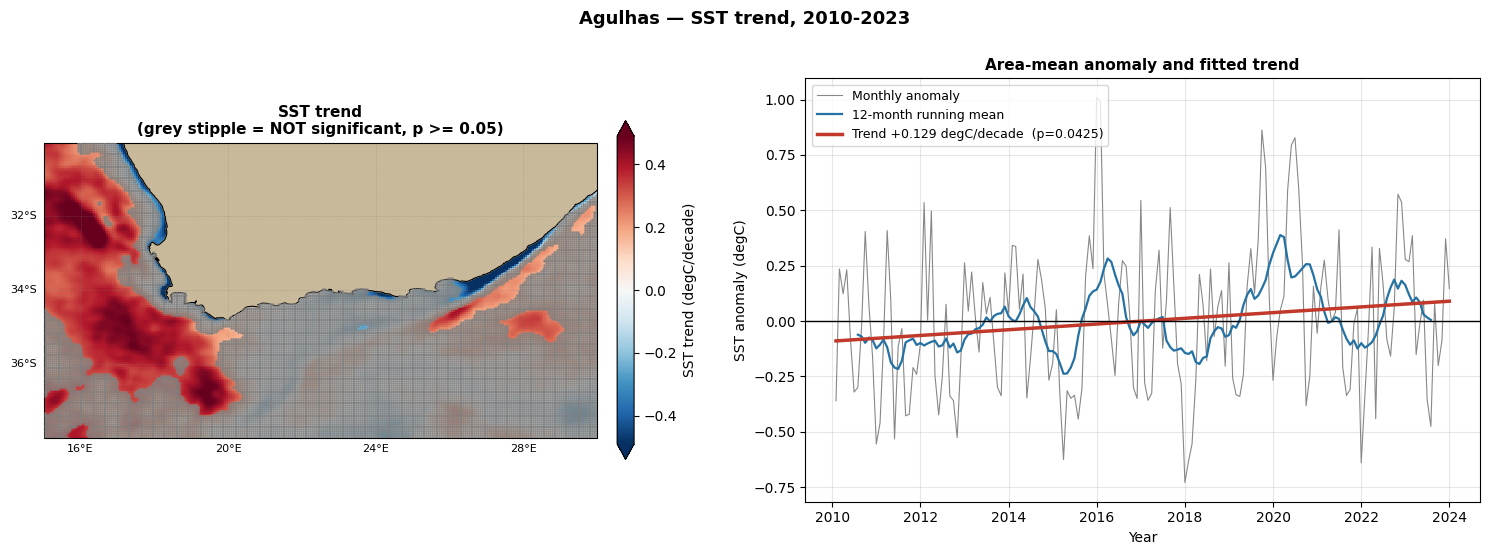

   19% of grid points show a significant trend (p < 0.05)
   Median slope where significant: +0.351 degC/decade

   HOW TO REPORT THIS
   Say  : "SST rose by about 0.2 degC over 2010-2023."
   Avoid: "the region is warming at 0.13 degC per decade."
   The first is a statement about the record. The second implies
   a rate that will continue, which 14 years cannot establish.


In [ ]:
# ============================================================
# 2.10 — IS THE WARMING REAL? LINEAR TREND AND SIGNIFICANCE
# ─────────────────────────────────────────────────────────────
# In 2.5 we compared 2010-2015 with 2018-2023 by eye. That is
# not enough: 14 years of a noisy series can produce an
# apparent difference by chance.
#
# A least-squares fit gives a slope in degC/decade AND a
# p-value. p < 0.05 is the usual bar for "unlikely to be noise".
#
# CAVEAT WORTH STATING OUT LOUD: 14 years is SHORT for a climate
# trend. If the record happens to start in a cool period and end
# in a warm one, any straight line through it will be steep.
# Report it as "SST rose by X over this record", not "the region
# is warming at X per decade".
# ============================================================

import warnings
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ---- 1. area-mean trend ----
t_years = (area_anom.index - area_anom.index[0]).days / 365.25
res = stats.linregress(t_years, area_anom.values)
span = float(t_years[-1] - t_years[0])

print('AREA-MEAN TREND')
print(f'   slope      : {res.slope*10:+.3f} degC per decade')
print(f'   p-value    : {res.pvalue:.4g}')
print(f'   r-squared  : {res.rvalue**2:.3f}')
print(f'   std error  : {res.stderr*10:.3f} degC/decade')
print(f'   total rise : {res.slope*span:+.2f} degC over {span:.0f} years')
print()
if res.pvalue < 0.05:
    print('   Statistically significant at p < 0.05.')
else:
    print('   NOT significant at p < 0.05. The apparent change is within')
    print('   what 14 years of natural variability can produce. Report it')
    print('   as "no detectable trend", not "no warming".')
print()

# how much of the slope is an artefact of where the record starts and ends?
first3 = area_anom.iloc[:36].mean()
last3  = area_anom.iloc[-36:].mean()
print(f'   First 3 years mean anomaly : {first3:+.3f} degC')
print(f'   Last  3 years mean anomaly : {last3:+.3f} degC')
print('   If the record begins in a cool spell and ends in a warm one,')
print('   a straight line will exaggerate the underlying rate.')
print()

# ---- 2. per-pixel trend map ----
print('Computing the trend at every grid point...')
mon = sst_anom
tt  = (mon.time - mon.time[0]).dt.days.values / 365.25

def _fit(y):
    if np.isnan(y).all():
        return np.array([np.nan, np.nan])
    ok = ~np.isnan(y)
    if ok.sum() < 24:
        return np.array([np.nan, np.nan])
    r = stats.linregress(tt[ok], y[ok])
    return np.array([r.slope * 10, r.pvalue])      # degC/decade, p

out = xr.apply_ufunc(_fit, mon,
                     input_core_dims=[['time']],
                     output_core_dims=[['stat']],
                     vectorize=True, dask='parallelized',
                     output_dtypes=[float],
                     dask_gufunc_kwargs={'output_sizes': {'stat': 2}}).compute()

slope_map = out.isel(stat=0)
pval_map  = out.isel(stat=1)
print('Done.\n')

print('P-VALUE MAP DIAGNOSTICS')
print(f'   min {float(pval_map.min()):.3g}   '
      f'median {float(pval_map.median()):.3g}   '
      f'max {float(pval_map.max()):.3g}')
print(f'   grid points with p < 0.05 : '
      f'{float((pval_map < 0.05).mean())*100:.1f}%')
print(f'   NaN grid points (land)    : {int(pval_map.isnull().sum())}')
print()

# ---- 3. plot ----
aspect = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
fig = plt.figure(figsize=(15, max(5.5, 5.5 / aspect + 1.5)))

ax1 = fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree())
lim = float(abs(slope_map).quantile(0.98))
slope_map.plot(ax=ax1, transform=ccrs.PlateCarree(), cmap='RdBu_r',
               vmin=-lim, vmax=lim, extend='both',
               cbar_kwargs={'label': 'SST trend (degC/decade)',
                            'shrink': 0.8, 'pad': 0.03},
               add_labels=False)

# stipple where the trend is NOT significant.
# Use pval_map's own coordinates so nothing can transpose, and
# exclude land (NaN) explicitly rather than relying on isnan.
pv = pval_map.values
not_sig = (pv >= 0.05) & ~np.isnan(pv)
yy, xx = np.meshgrid(pval_map.latitude.values,
                     pval_map.longitude.values, indexing='ij')
if not_sig.any():
    ax1.scatter(xx[not_sig], yy[not_sig], s=0.8, color='gray', alpha=0.7,
                transform=ccrs.PlateCarree(), zorder=5)
print(f'   stippled (not significant): {int(not_sig.sum())} of '
      f'{int((~np.isnan(pv)).sum())} ocean points')
print()

ax1.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax1.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
gl = ax1.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                   alpha=0.4, linestyle='--')
gl.top_labels = False; gl.right_labels = False
gl.xlocator = mticker.MaxNLocator(4); gl.ylocator = mticker.MaxNLocator(4)
gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}
ax1.set_title('SST trend\n(grey stipple = NOT significant, p >= 0.05)',
              fontsize=11, fontweight='bold')

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(area_anom.index, area_anom.values, color='#888888', lw=0.8,
         label='Monthly anomaly')
roll12 = area_anom.rolling(12, center=True).mean()
ax2.plot(roll12.index, roll12.values, color='#2471a3', lw=1.6,
         label='12-month running mean')
fit = res.intercept + res.slope * t_years
ax2.plot(area_anom.index, fit, color='#c0392b', lw=2.5,
         label=f'Trend {res.slope*10:+.3f} degC/decade  (p={res.pvalue:.3g})')
ax2.axhline(0, color='black', lw=1)
ax2.set_xlabel('Year', fontsize=10)
ax2.set_ylabel('SST anomaly (degC)', fontsize=10)
ax2.set_title('Area-mean anomaly and fitted trend', fontsize=11, fontweight='bold')
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

fig.suptitle(f'{ZONE_NAME} — SST trend, {DATE_START[:4]}-{DATE_END[:4]}',
             fontsize=13, fontweight='bold', y=1.00)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_trend_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

sig_frac = float((pval_map < 0.05).mean()) * 100
print(f'   {sig_frac:.0f}% of grid points show a significant trend (p < 0.05)')
if sig_frac > 0:
    print(f'   Median slope where significant: '
          f'{float(slope_map.where(pval_map < 0.05).median()):+.3f} degC/decade')
print()
print('   HOW TO REPORT THIS')
print(f'   Say  : "SST rose by about {res.slope*span:.1f} degC over 2010-2023."')
print(f'   Avoid: "the region is warming at {res.slope*10:.2f} degC per decade."')
print('   The first is a statement about the record. The second implies')
print('   a rate that will continue, which 14 years cannot establish.')

In [ ]:
print(f'p-value map : min {float(pval_map.min()):.3g}  '
      f'median {float(pval_map.median()):.3g}  '
      f'max {float(pval_map.max()):.3g}')
print(f'p < 0.05    : {float((pval_map < 0.05).mean())*100:.1f}% of points')
print()
# what is actually being fitted?
print('sst_monthly is:', sst_monthly.attrs.get('long_name', 'SST'))
pt = sst_monthly.isel(latitude=len(sst_monthly.latitude)//2,
                      longitude=len(sst_monthly.longitude)//2)
print(f'   one pixel: min {float(pt.min()):.1f}, max {float(pt.max()):.1f} degC')
print('   -> if that range is several degC, you are fitting the SEASONAL')
print('      CYCLE, not the trend. Fit the anomaly instead.')

p-value map : min 4.85e-13  median 0.192  max 1
p < 0.05    : 19.2% of points

sst_monthly is: Sea Surface Temperature
   one pixel: min nan, max nan degC
   -> if that range is several degC, you are fitting the SEASONAL
      CYCLE, not the trend. Fit the anomaly instead.


Climatology across the year boundary (should step smoothly):
   364:21.09  365:21.12  366:21.15  1:21.17  2:21.20  3:21.23

Agulhas: 38 events detected

   Event shown (2015-16, position 14):
     2015-12-02 to 2016-01-15
     duration 45 days, max 2.16 degC, cumulative 50.75 degC-days
     peak day 2016-01-05  (day 35 of 45)

   Monthly mean excess over climatology during this event:
   time
   2015-12-31    1.03
   2016-01-31    1.32
   Freq: ME

   Which event tops each metric:
     MHW Duration               position  23  2019-08-22  61.00 days
     MHW Maximum Intensity      position  14  2015-12-02  2.16 degC   <- same as the event shown
     MHW Cumulative Intensity   position  14  2015-12-02  50.75 degC-days   <- same as the event shown


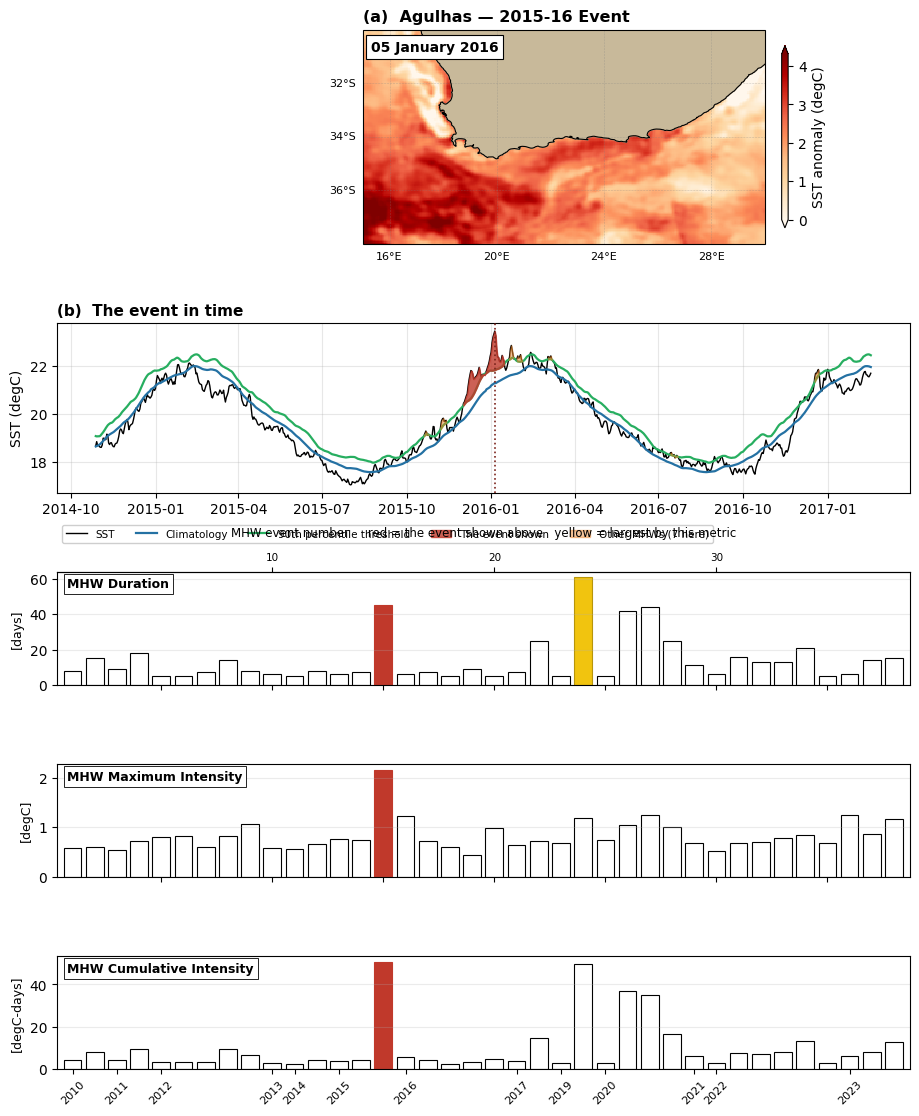


   Top five events by CUMULATIVE intensity:
   rank  pos  start        end          days   max degC   degC-days
      1   14  2015-12-02   2016-01-15     45       2.16       50.75
      2   23  2019-08-22   2019-10-21     61       1.19       49.53
      3   25  2020-04-15   2020-05-26     42       1.05       36.89
      4   26  2020-05-30   2020-07-12     44       1.25       34.96
      5   27  2020-07-17   2020-08-10     25       1.00       16.75

   THE POINT OF THIS FIGURE
   Where red and yellow sit in different places, the longest,
   the most intense and the most damaging events are three
   different events. Cumulative intensity is the one that
   matters biologically: a long moderate event does more harm
   than a brief extreme one.

   CAVEAT: Hobday uses a 30-year baseline (1983-2012). Ours is 14
   years, entirely within a warmer period, so our threshold is
   elevated and this UNDERCOUNTS events relative to published work.


In [ ]:
# ============================================================
# 2.11 — HOBDAY-STYLE MHW SUMMARY FOR YOUR ZONE
# ─────────────────────────────────────────────────────────────
# Reproduces the standard figure from Hobday et al. (2016),
# Fig. 3:
#
#   Row 1  SST anomaly on the PEAK DAY of the event.
#          Date in a white box INSIDE the map, as in the paper.
#   Row 2  climatology (blue), 90th percentile threshold (green),
#          SST (black). The event shown filled RED, every other
#          MHW in the window filled ORANGE.
#   Rows 3-5  every event ranked by duration, maximum intensity
#          and cumulative intensity.
#          RED    = the event shown above
#          YELLOW = the largest event by that metric
#
# BUG FIXED IN THIS VERSION
# The earlier smooth_cyclic() concatenated the head and tail of
# the series, producing a NON-MONOTONIC index. A centred rolling
# mean over that distorts the climatology within ~10 days of the
# year boundary — which made events spanning New Year appear to
# peak on 1 January. It now pads the VALUES instead, so the wrap
# is genuine and the index stays clean.
#
# Cumulative intensity is the biologically meaningful metric:
# 30 days at +1 degC stresses an ecosystem more than 3 days at
# +3 degC, and only the integral captures that.
# ============================================================

import warnings
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

WINDOW_DAYS = 400          # context either side of the event in row 2

# ---- 1. daily area mean, climatology, threshold ----
daily = sst.mean(['latitude', 'longitude']).to_series()
doy   = daily.index.dayofyear


def smooth_cyclic(s, window=11):
    """Rolling mean that genuinely wraps 31 Dec into 1 Jan.

    Pads the VALUES at both ends and convolves, so the index
    never becomes non-monotonic. Concatenating head and tail
    (the previous approach) distorted the climatology within
    ~10 days of the year boundary.
    """
    s = s.sort_index()
    v = s.values.astype(float)
    n = len(v)
    pad = np.concatenate([v[-window:], v, v[:window]])
    kern = np.ones(window) / window
    sm = np.convolve(pad, kern, mode='same')[window:window + n]
    return pd.Series(sm, index=s.index)


clim_s = smooth_cyclic(daily.groupby(doy).mean())
p90_s  = smooth_cyclic(daily.groupby(doy).quantile(0.90))
clim_line = pd.Series(doy, index=daily.index).map(clim_s)
p90_line  = pd.Series(doy, index=daily.index).map(p90_s)

# quick check that the wrap is now smooth
edge = pd.concat([clim_s.iloc[-3:], clim_s.iloc[:3]])
print('Climatology across the year boundary (should step smoothly):')
print('   ' + '  '.join(f'{d}:{v:.2f}' for d, v in edge.items()))
print()

# ---- 2. detect events (>90th pct, >=5 days, gaps <=2 joined) ----
above = (daily > p90_line).values
d = np.diff(np.concatenate(([0], above.view(np.int8), [0])))
starts, ends = np.where(d == 1)[0], np.where(d == -1)[0] - 1

joined = []
for a_, b_ in zip(starts, ends):
    if joined and a_ - joined[-1][1] <= 3:
        joined[-1] = (joined[-1][0], b_)
    else:
        joined.append((a_, b_))
events = [(a_, b_) for a_, b_ in joined if (b_ - a_ + 1) >= 5]

rec = []
for a_, b_ in events:
    e = daily.iloc[a_:b_+1] - clim_line.iloc[a_:b_+1]
    rec.append(dict(start=daily.index[a_], end=daily.index[b_],
                    duration=b_ - a_ + 1,
                    max_int=float(e.max()),
                    cum_int=float(e.sum()),
                    peak_day=e.idxmax()))          # PEAK DAY, as in Hobday
ev = pd.DataFrame(rec).reset_index(drop=True)

if len(ev) == 0:
    print(f'No marine heatwaves detected in {ZONE_NAME}. Nothing to plot.')
else:
    biggest  = int(ev['cum_int'].values.argmax())
    a, b     = events[biggest]
    exc      = daily.iloc[a:b+1] - clim_line.iloc[a:b+1]
    peak_day = exc.idxmax()

    y0 = ev.iloc[biggest]['start'].year
    y1 = ev.iloc[biggest]['end'].year
    yr_label = f'{y0}' if y0 == y1 else f'{y0}-{str(y1)[-2:]}'

    print(f'{ZONE_NAME}: {len(ev)} events detected\n')
    print(f'   Event shown ({yr_label}, position {biggest}):')
    print(f'     {ev.iloc[biggest]["start"]:%Y-%m-%d} to {ev.iloc[biggest]["end"]:%Y-%m-%d}')
    print(f'     duration {ev.iloc[biggest]["duration"]} days, '
          f'max {ev.iloc[biggest]["max_int"]:.2f} degC, '
          f'cumulative {ev.iloc[biggest]["cum_int"]:.2f} degC-days')
    print(f'     peak day {peak_day:%Y-%m-%d}  '
          f'(day {(peak_day - ev.iloc[biggest]["start"]).days + 1} of '
          f'{ev.iloc[biggest]["duration"]})')
    print()
    print('   Monthly mean excess over climatology during this event:')
    print('   ' + exc.resample('ME').mean().round(2).to_string().replace('\n', '\n   '))
    print()

    # ---- 3. figure ----
    fig = plt.figure(figsize=(11, 13.5))
    gs = fig.add_gridspec(5, 1, height_ratios=[1.9, 1.5, 1, 1, 1], hspace=0.55)

    # ROW 1 — SST anomaly on the peak day
    ax = fig.add_subplot(gs[0], projection=ccrs.PlateCarree())
    clim_field = sst.groupby('time.dayofyear').mean('time')
    snap = (sst.sel(time=peak_day, method='nearest')
            - clim_field.sel(dayofyear=int(peak_day.dayofyear))).compute()
    lim = max(float(abs(snap).quantile(0.99)), 0.5)
    snap.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='OrRd',
              vmin=0, vmax=lim, extend='both',
              cbar_kwargs={'label': 'SST anomaly (degC)', 'shrink': 0.85,
                           'pad': 0.02, 'aspect': 28},
              add_labels=False)
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    gl.xlocator = mticker.MaxNLocator(4); gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}

    ax.text(0.02, 0.95, f'{peak_day:%d %B %Y}',
            transform=ax.transAxes, fontsize=10, fontweight='bold',
            va='top', ha='left', zorder=8,
            bbox=dict(facecolor='white', edgecolor='black',
                      linewidth=0.8, boxstyle='square,pad=0.35'))

    ax.set_title(f'(a)  {ZONE_NAME} — {yr_label} Event',
                 fontsize=11.5, fontweight='bold', loc='left')

    # ROW 2 — the event in context
    ax = fig.add_subplot(gs[1])
    lo = max(0, a - WINDOW_DAYS)
    hi = min(len(daily) - 1, b + WINDOW_DAYS)
    win = slice(lo, hi)
    ax.plot(daily.index[win], daily.values[win], color='black', lw=1.0, label='SST')
    ax.plot(daily.index[win], clim_line.values[win], color='#2471a3', lw=1.6,
            label='Climatology')
    ax.plot(daily.index[win], p90_line.values[win], color='#27ae60', lw=1.6,
            label='90th percentile threshold')

    n_other = 0
    for (ea, eb) in events:
        if ea > hi or eb < lo:
            continue
        is_shown = (ea, eb) == (a, b)
        if not is_shown:
            n_other += 1
        ax.fill_between(daily.index[ea:eb+1],
                        p90_line.iloc[ea:eb+1], daily.iloc[ea:eb+1],
                        color='#c0392b' if is_shown else '#e67e22',
                        alpha=0.80 if is_shown else 0.45,
                        zorder=4 if is_shown else 3)

    ax.axvline(peak_day, color='#7b241c', lw=1.2, ls=':', zorder=6)

    handles, _ = ax.get_legend_handles_labels()
    handles += [mpatches.Patch(color='#c0392b', alpha=0.80, label='The event shown'),
                mpatches.Patch(color='#e67e22', alpha=0.45,
                               label=f'Other MHWs ({n_other} here)')]
    ax.set_ylabel('SST (degC)', fontsize=10)
    ax.set_title('(b)  The event in time', fontsize=11, fontweight='bold', loc='left')
    ax.legend(handles=handles, fontsize=7.5, loc='upper left',
              bbox_to_anchor=(0.0, -0.16), ncol=5, framealpha=0.95)
    ax.grid(True, alpha=0.3)

    # ROWS 3-5 — every event, three metrics
    x = np.arange(1, len(ev) + 1)
    metrics = [('duration', 'MHW Duration',             'days'),
               ('max_int',  'MHW Maximum Intensity',    'degC'),
               ('cum_int',  'MHW Cumulative Intensity', 'degC-days')]

    print('   Which event tops each metric:')
    for k, (col, label, unit) in enumerate(metrics):
        ax = fig.add_subplot(gs[2 + k])
        bars = ax.bar(x, ev[col].values, color='white',
                      edgecolor='black', linewidth=0.8)

        top_here = int(ev[col].values.argmax())
        if top_here != biggest:
            bars[top_here].set_facecolor('#f1c40f')
            bars[top_here].set_edgecolor('#b7950b')
        bars[biggest].set_facecolor('#c0392b')
        bars[biggest].set_edgecolor('#c0392b')

        same = '   <- same as the event shown' if top_here == biggest else ''
        print(f'     {label:<26} position {top_here:>3}  '
              f'{ev.iloc[top_here]["start"]:%Y-%m-%d}  '
              f'{ev.iloc[top_here][col]:.2f} {unit}{same}')

        ax.set_ylabel(f'[{unit}]', fontsize=9)
        ax.set_xlim(0.3, len(ev) + 0.7)
        ax.grid(True, alpha=0.25, axis='y')
        ax.text(0.012, 0.86, label, transform=ax.transAxes, fontsize=9,
                fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='black', linewidth=0.6,
                          boxstyle='square,pad=0.3'))
        if k == 0:
            ax.set_title('MHW event number     '
                         'red = the event shown above   '
                         'yellow = largest by this metric',
                         fontsize=8.5, loc='center', pad=26)
            axt = ax.secondary_xaxis('top')
            ticks = list(range(10, len(ev) + 1, 10))
            axt.set_xticks(ticks)
            axt.set_xticklabels([str(t) for t in ticks], fontsize=7.5)
        if k == 2:
            yr_of = ev['start'].dt.year.values
            ticks = [i + 1 for i in range(len(ev))
                     if i == 0 or yr_of[i] != yr_of[i-1]]
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(yr_of[t-1]) for t in ticks],
                               rotation=45, fontsize=8)
        else:
            ax.set_xticklabels([])

    plt.savefig(f'{OUTPUT_DIR}/Day2_MHW_hobday_{FILE_PREFIX}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    print()
    print('   Top five events by CUMULATIVE intensity:')
    print('   rank  pos  start        end          days   max degC   degC-days')
    for rank, pos in enumerate(np.argsort(-ev['cum_int'].values)[:5], 1):
        r = ev.iloc[pos]
        print(f'   {rank:>4}  {pos:>3}  {r["start"]:%Y-%m-%d}   {r["end"]:%Y-%m-%d}   '
              f'{r["duration"]:>4}   {r["max_int"]:>8.2f}   {r["cum_int"]:>9.2f}')
    print()
    print('   THE POINT OF THIS FIGURE')
    print('   Where red and yellow sit in different places, the longest,')
    print('   the most intense and the most damaging events are three')
    print('   different events. Cumulative intensity is the one that')
    print('   matters biologically: a long moderate event does more harm')
    print('   than a brief extreme one.')
    print()
    print('   CAVEAT: Hobday uses a 30-year baseline (1983-2012). Ours is 14')
    print('   years, entirely within a warmer period, so our threshold is')
    print('   elevated and this UNDERCOUNTS events relative to published work.')

Building climatology and threshold (pooled 11-day window)...
Done.

Climatology across the year boundary (should step smoothly):
   364:21.06  365:21.09  366:21.12  1:21.15  2:21.18  3:21.21

Agulhas: 28 events detected

   EVENT SHOWN — 2019 (position 15)
     period      : 2019-09-04 to 2019-10-21
     peak day    : 2019-10-19  (day 46 of 48)
     D           : 48 days
     i_max       : 1.19 degC
     i_mean      : 0.86 degC
     i_cum       : 41.4 degC-days
     r_onset     : 0.026 degC/day
     r_decline   : 0.595 degC/day
     shape       : slow onset, fast decline   (see Fig. 2 of the paper)

   Rank of this event on each metric (1 = largest):
     duration         rank 1 of 28
     max intensity    rank 6 of 28
     mean intensity   rank 6 of 28
     cumulative       rank 1 of 28

   Monthly mean intensity during this event:
   time
   2019-09-30    0.90
   2019-10-31    0.82
   Freq: ME

   Which event tops each metric:
     MHW Duration (D)             position  15  2019-09-0

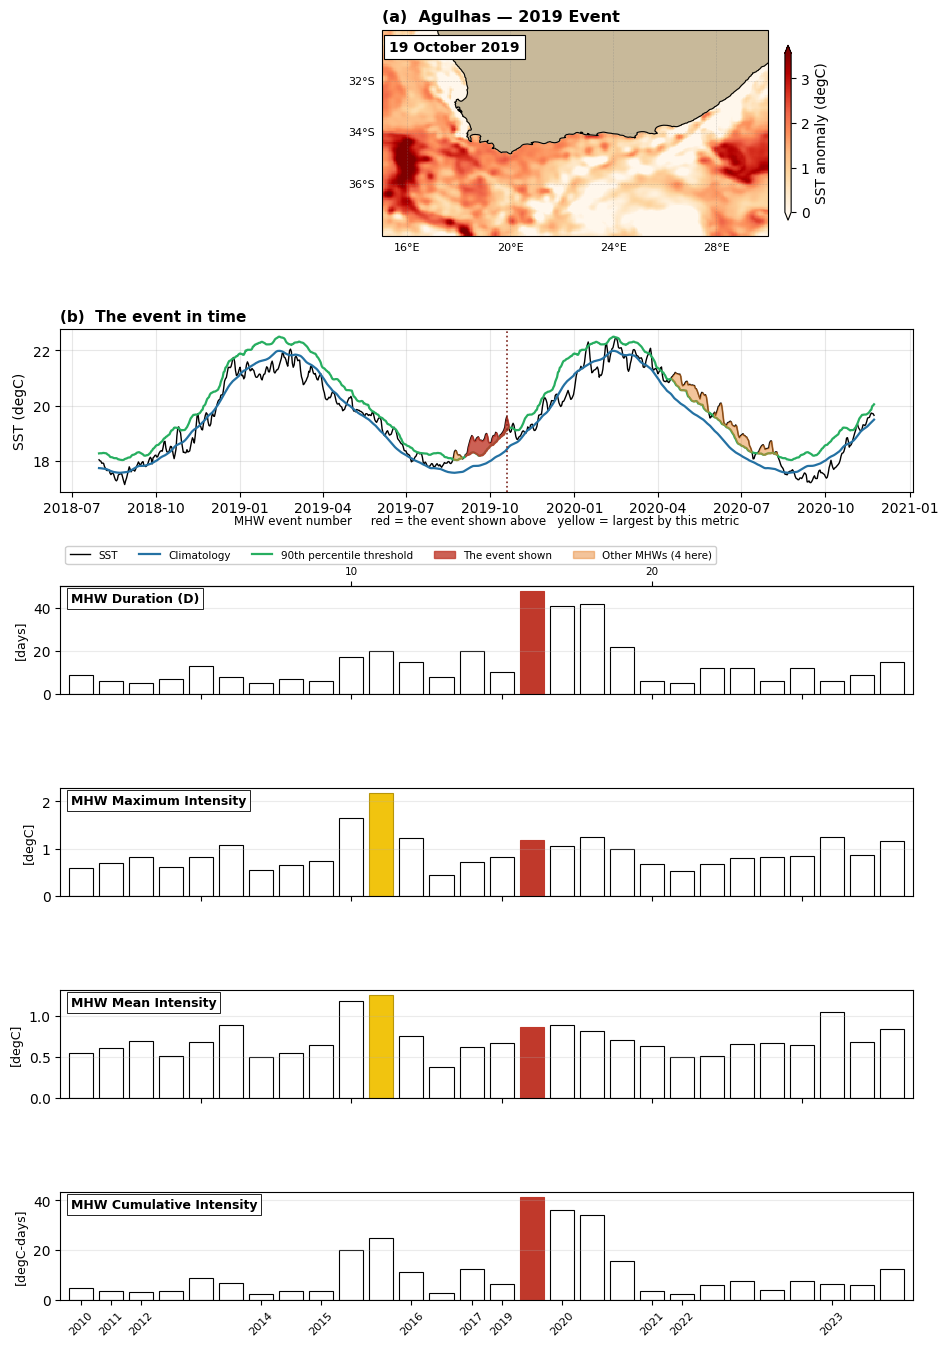


   TOP FIVE EVENTS BY CUMULATIVE INTENSITY  (full metric set)
   pos  start        end            D   i_max  i_mean   i_cum  r_onset  r_decl
    15  2019-09-04   2019-10-21    48    1.19    0.86    41.4    0.026   0.595
    16  2020-04-16   2020-05-26    41    1.05    0.89    36.4    0.117   0.034
    17  2020-06-01   2020-07-12    42    1.25    0.81    34.0    0.156   0.038
    10  2015-12-27   2016-01-15    20    2.18    1.25    25.0    0.242   0.218
     9  2015-12-04   2015-12-20    17    1.65    1.18    20.0    0.276   0.165

   READING THE RATES  (Fig. 2 of the paper)
   r_onset >> r_decline : fast build, slow fade — organisms get
     little warning, which is the damaging pattern.
   r_onset << r_decline : slow build, abrupt end.
   Two events with the same D and i_max can have very different
   i_cum depending on which shape they have.

   CAVEAT: Hobday recommends a 30-year baseline (1983-2012).
   Ours is 14 years, entirely within a warmer period, so the
   threshold is elev

In [ ]:
# ============================================================
# 2.12 — HOBDAY-STYLE MHW SUMMARY  (full metric set)
# ─────────────────────────────────────────────────────────────
# Follows Hobday et al. (2016), Prog. Oceanogr. 141: 227-238.
#
# CLIMATOLOGY AND THRESHOLD  (their Section 2.1)
#   For each day of year, pool ALL days falling within an
#   11-day window centred on it, across ALL years, then take
#   the mean and the 90th percentile of that pool.
#   This is NOT the same as computing a per-day percentile and
#   smoothing afterwards — pooling uses ~150 values per day
#   instead of 14, so the estimate is far better sampled.
#
# EVENT DEFINITION
#   >90th percentile, >=5 days, gaps of <=2 days joined.
#
# METRICS  (their Fig. 1)
#   D          duration, days
#   i_max      maximum intensity, degC above climatology
#   i_mean     mean intensity over the event
#   i_cum      cumulative intensity, degC-days (the integral)
#   r_onset    rate of warming to the peak, degC/day
#   r_decline  rate of cooling from the peak, degC/day
#
# Fig. 2 of the paper is entirely about why the rates matter:
# two events with identical D and i_max can differ greatly in
# i_cum depending on whether onset was fast or slow.
#
# BASELINE CAVEAT: they recommend 30 years (1983-2012). We have
# 14, entirely within a warmer period, so our threshold is
# elevated and this UNDERCOUNTS events relative to published work.
# ============================================================

import warnings
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

WINDOW_DAYS = 400          # context either side of the event in row 2
CLIM_WINDOW = 11           # Hobday: 11-day window centred on each day of year
PCTILE      = 90           # Hobday: 90th percentile threshold
MIN_DAYS    = 5            # Hobday: minimum duration
MAX_GAP     = 2            # Hobday: gaps of <=2 days are joined

# ---- 1. daily area mean ----
daily = sst.mean(['latitude', 'longitude']).to_series()
doy   = np.asarray(daily.index.dayofyear)


def clim_and_threshold(series, window=CLIM_WINDOW, pctile=PCTILE):
    """Climatology and percentile threshold, Hobday method.

    For each day of year d, pool every observation whose day of
    year lies within +/- (window//2) of d, across all years, and
    take the mean and the percentile of that pool. The window
    wraps around the year boundary.
    """
    d_of_y = np.asarray(series.index.dayofyear)
    half   = window // 2
    clim, thr = {}, {}
    for d in range(1, 367):
        offs = [((d - 1 + k) % 366) + 1 for k in range(-half, half + 1)]
        pool = series.values[np.isin(d_of_y, offs)]
        if len(pool) == 0:
            clim[d], thr[d] = np.nan, np.nan
        else:
            clim[d] = float(np.nanmean(pool))
            thr[d]  = float(np.nanpercentile(pool, pctile))
    c = pd.Series(clim).interpolate().bfill().ffill()
    t = pd.Series(thr).interpolate().bfill().ffill()
    return c, t


print('Building climatology and threshold (pooled 11-day window)...')
clim_s, p90_s = clim_and_threshold(daily)
clim_line = pd.Series(doy, index=daily.index).map(clim_s)
p90_line  = pd.Series(doy, index=daily.index).map(p90_s)
print('Done.\n')

print('Climatology across the year boundary (should step smoothly):')
edge = pd.concat([clim_s.iloc[-3:], clim_s.iloc[:3]])
print('   ' + '  '.join(f'{d}:{v:.2f}' for d, v in edge.items()))
print()

# ---- 2. detect events ----
above = (daily > p90_line).values
d_ = np.diff(np.concatenate(([0], above.view(np.int8), [0])))
starts, ends = np.where(d_ == 1)[0], np.where(d_ == -1)[0] - 1

joined = []
for a_, b_ in zip(starts, ends):
    if joined and a_ - joined[-1][1] <= MAX_GAP + 1:
        joined[-1] = (joined[-1][0], b_)
    else:
        joined.append((a_, b_))
events = [(a_, b_) for a_, b_ in joined if (b_ - a_ + 1) >= MIN_DAYS]

rec = []
for a_, b_ in events:
    e = daily.iloc[a_:b_+1] - clim_line.iloc[a_:b_+1]     # intensity vs climatology
    ip = int(np.argmax(e.values))                          # position of the peak
    rec.append(dict(
        start     = daily.index[a_],
        end       = daily.index[b_],
        peak_day  = e.index[ip],
        duration  = b_ - a_ + 1,
        i_max     = float(e.iloc[ip]),
        i_mean    = float(e.mean()),
        i_cum     = float(e.sum()),
        r_onset   = float(e.iloc[ip] / max(ip, 1)),
        r_decline = float(e.iloc[ip] / max(len(e) - 1 - ip, 1)),
    ))
ev = pd.DataFrame(rec).reset_index(drop=True)

if len(ev) == 0:
    print(f'No marine heatwaves detected in {ZONE_NAME}. Nothing to plot.')
else:
    biggest  = int(ev['i_cum'].values.argmax())
    a, b     = events[biggest]
    exc      = daily.iloc[a:b+1] - clim_line.iloc[a:b+1]
    peak_day = ev.iloc[biggest]['peak_day']

    y0, y1 = ev.iloc[biggest]['start'].year, ev.iloc[biggest]['end'].year
    yr_label = f'{y0}' if y0 == y1 else f'{y0}-{str(y1)[-2:]}'

    r = ev.iloc[biggest]
    print(f'{ZONE_NAME}: {len(ev)} events detected\n')
    print(f'   EVENT SHOWN — {yr_label} (position {biggest})')
    print(f'     period      : {r["start"]:%Y-%m-%d} to {r["end"]:%Y-%m-%d}')
    print(f'     peak day    : {r["peak_day"]:%Y-%m-%d}  '
          f'(day {(r["peak_day"] - r["start"]).days + 1} of {r["duration"]})')
    print(f'     D           : {r["duration"]} days')
    print(f'     i_max       : {r["i_max"]:.2f} degC')
    print(f'     i_mean      : {r["i_mean"]:.2f} degC')
    print(f'     i_cum       : {r["i_cum"]:.1f} degC-days')
    print(f'     r_onset     : {r["r_onset"]:.3f} degC/day')
    print(f'     r_decline   : {r["r_decline"]:.3f} degC/day')
    shape = ('fast onset, slow decline' if r['r_onset'] > 1.5 * r['r_decline']
             else 'slow onset, fast decline' if r['r_decline'] > 1.5 * r['r_onset']
             else 'roughly symmetric')
    print(f'     shape       : {shape}   (see Fig. 2 of the paper)')
    print()

    # rank of this event on each metric — the headline for the plenary
    print('   Rank of this event on each metric (1 = largest):')
    for col, lab in [('duration', 'duration'), ('i_max', 'max intensity'),
                     ('i_mean', 'mean intensity'), ('i_cum', 'cumulative')]:
        rank = int((ev[col] > r[col]).sum()) + 1
        print(f'     {lab:<16} rank {rank} of {len(ev)}')
    print()
    print('   Monthly mean intensity during this event:')
    print('   ' + exc.resample('ME').mean().round(2).to_string().replace('\n', '\n   '))
    print()

    # ---- 3. figure ----
    fig = plt.figure(figsize=(11, 16.5))
    gs = fig.add_gridspec(6, 1, height_ratios=[1.9, 1.5, 1, 1, 1, 1], hspace=0.70)

    # ROW 1 — SST anomaly on the peak day
    ax = fig.add_subplot(gs[0], projection=ccrs.PlateCarree())
    clim_field = sst.groupby('time.dayofyear').mean('time')
    snap = (sst.sel(time=peak_day, method='nearest')
            - clim_field.sel(dayofyear=int(peak_day.dayofyear))).compute()
    lim = max(float(abs(snap).quantile(0.99)), 0.5)
    snap.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='OrRd',
              vmin=0, vmax=lim, extend='both',
              cbar_kwargs={'label': 'SST anomaly (degC)', 'shrink': 0.85,
                           'pad': 0.02, 'aspect': 28},
              add_labels=False)
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    gl.xlocator = mticker.MaxNLocator(4); gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}
    ax.text(0.02, 0.95, f'{peak_day:%d %B %Y}',
            transform=ax.transAxes, fontsize=10, fontweight='bold',
            va='top', ha='left', zorder=8,
            bbox=dict(facecolor='white', edgecolor='black',
                      linewidth=0.8, boxstyle='square,pad=0.35'))
    ax.set_title(f'(a)  {ZONE_NAME} — {yr_label} Event',
                 fontsize=11.5, fontweight='bold', loc='left')

    # ROW 2 — the event in context
    ax = fig.add_subplot(gs[1])
    lo = max(0, a - WINDOW_DAYS)
    hi = min(len(daily) - 1, b + WINDOW_DAYS)
    win = slice(lo, hi)
    ax.plot(daily.index[win], daily.values[win], color='black', lw=1.0, label='SST')
    ax.plot(daily.index[win], clim_line.values[win], color='#2471a3', lw=1.6,
            label='Climatology')
    ax.plot(daily.index[win], p90_line.values[win], color='#27ae60', lw=1.6,
            label='90th percentile threshold')

    n_other = 0
    for (ea, eb) in events:
        if ea > hi or eb < lo:
            continue
        shown = (ea, eb) == (a, b)
        if not shown:
            n_other += 1
        ax.fill_between(daily.index[ea:eb+1],
                        p90_line.iloc[ea:eb+1], daily.iloc[ea:eb+1],
                        color='#c0392b' if shown else '#e67e22',
                        alpha=0.80 if shown else 0.45,
                        zorder=4 if shown else 3)
    ax.axvline(peak_day, color='#7b241c', lw=1.2, ls=':', zorder=6)

    handles, _ = ax.get_legend_handles_labels()
    handles += [mpatches.Patch(color='#c0392b', alpha=0.80, label='The event shown'),
                mpatches.Patch(color='#e67e22', alpha=0.45,
                               label=f'Other MHWs ({n_other} here)')]
    ax.set_ylabel('SST (degC)', fontsize=10)
    ax.set_title('(b)  The event in time', fontsize=11, fontweight='bold', loc='left')
    ax.legend(handles=handles, fontsize=7.5, loc='upper left',
              bbox_to_anchor=(0.0, -0.30), ncol=5, framealpha=0.95)
    ax.grid(True, alpha=0.3)

    # ROWS 3-6 — every event, four metrics
    x = np.arange(1, len(ev) + 1)
    metrics = [('duration', 'MHW Duration (D)',         'days'),
               ('i_max',    'MHW Maximum Intensity',    'degC'),
               ('i_mean',   'MHW Mean Intensity',       'degC'),
               ('i_cum',    'MHW Cumulative Intensity', 'degC-days')]

    print('   Which event tops each metric:')
    for k, (col, label, unit) in enumerate(metrics):
        ax = fig.add_subplot(gs[2 + k])
        bars = ax.bar(x, ev[col].values, color='white',
                      edgecolor='black', linewidth=0.8)
        top_here = int(ev[col].values.argmax())
        if top_here != biggest:
            bars[top_here].set_facecolor('#f1c40f')
            bars[top_here].set_edgecolor('#b7950b')
        bars[biggest].set_facecolor('#c0392b')
        bars[biggest].set_edgecolor('#c0392b')

        same = '   <- same as the event shown' if top_here == biggest else ''
        print(f'     {label:<28} position {top_here:>3}  '
              f'{ev.iloc[top_here]["start"]:%Y-%m-%d}  '
              f'{ev.iloc[top_here][col]:.2f} {unit}{same}')

        ax.set_ylabel(f'[{unit}]', fontsize=9)
        ax.set_xlim(0.3, len(ev) + 0.7)
        ax.grid(True, alpha=0.25, axis='y')
        ax.text(0.012, 0.85, label, transform=ax.transAxes, fontsize=9,
                fontweight='bold',
                bbox=dict(facecolor='white', edgecolor='black', linewidth=0.6,
                          boxstyle='square,pad=0.3'))
        if k == 0:
            ax.set_title('MHW event number     '
                         'red = the event shown above   '
                         'yellow = largest by this metric',
                         fontsize=8.5, loc='center', pad=44)
            axt = ax.secondary_xaxis('top')
            ticks = list(range(10, len(ev) + 1, 10))
            axt.set_xticks(ticks)
            axt.set_xticklabels([str(t) for t in ticks], fontsize=7.5)
        if k == len(metrics) - 1:
            yr_of = ev['start'].dt.year.values
            ticks = [i + 1 for i in range(len(ev))
                     if i == 0 or yr_of[i] != yr_of[i-1]]
            ax.set_xticks(ticks)
            ax.set_xticklabels([str(yr_of[t-1]) for t in ticks],
                               rotation=45, fontsize=8)
        else:
            ax.set_xticklabels([])

    plt.savefig(f'{OUTPUT_DIR}/Day2_MHW_hobday_{FILE_PREFIX}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    # ---- 4. full metric table ----
    print()
    print('   TOP FIVE EVENTS BY CUMULATIVE INTENSITY  (full metric set)')
    print('   pos  start        end            D   i_max  i_mean   i_cum  '
          'r_onset  r_decl')
    for pos in np.argsort(-ev['i_cum'].values)[:5]:
        q = ev.iloc[pos]
        print(f'   {pos:>3}  {q["start"]:%Y-%m-%d}   {q["end"]:%Y-%m-%d}  '
              f'{q["duration"]:>4}   {q["i_max"]:>5.2f}   {q["i_mean"]:>5.2f}  '
              f'{q["i_cum"]:>6.1f}    {q["r_onset"]:>5.3f}   {q["r_decline"]:>5.3f}')
    print()
    print('   READING THE RATES  (Fig. 2 of the paper)')
    print('   r_onset >> r_decline : fast build, slow fade — organisms get')
    print('     little warning, which is the damaging pattern.')
    print('   r_onset << r_decline : slow build, abrupt end.')
    print('   Two events with the same D and i_max can have very different')
    print('   i_cum depending on which shape they have.')
    print()
    print('   CAVEAT: Hobday recommends a 30-year baseline (1983-2012).')
    print('   Ours is 14 years, entirely within a warmer period, so the')
    print('   threshold is elevated and this UNDERCOUNTS events.')

Loading SSH altimetry...
   SSH: 1 file, 314 MB [staged]
   variables: ['sla', 'adt']
   shape (5113, 64, 120), 2010-01-01 to 2023-12-31

   domain-mean SLA: +6.2 cm
   (that offset is global sea level rise since the product
    reference period — not a feature of your region)

AREA-MEAN SEA LEVEL TREND
   slope     : +4.93 mm/year
   p-value   : 2.648e-15
   r-squared : 0.315
   total rise: +6.9 cm over 14 years

   For comparison, global mean sea level rise is currently
   about 3.3-4.5 mm/year. A regional value can differ a lot:
   winds, currents and ocean heat content all redistribute
   water regionally.

Computing the trend at every grid point...
Done.

   39% of grid points show a significant trend (p < 0.05)
   range: -7.8 to +17.0 mm/year



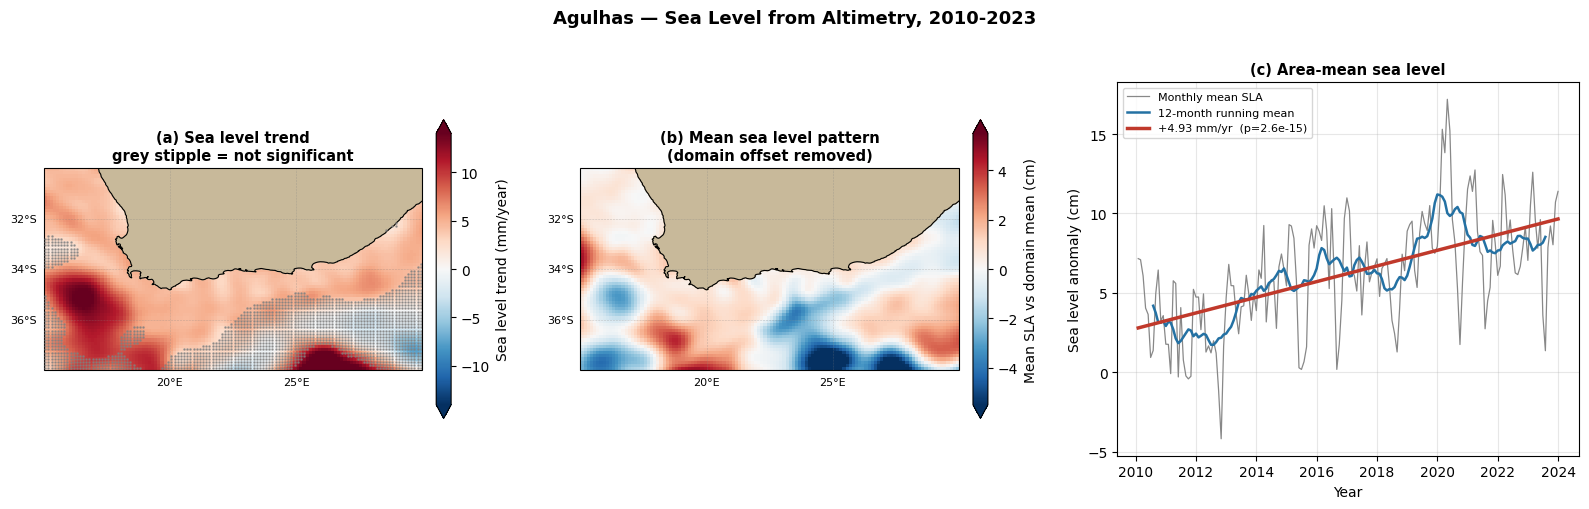

WHAT THIS MEANS FOR YOUR COAST
   Cape Point                  +5.08 mm/yr,  +7.1 cm over the record
   Mossel Bay                  +4.37 mm/yr,  +6.1 cm over the record
   Port Edward                 +4.07 mm/yr,  +5.7 cm over the record

   CAVEAT: altimetry degrades within ~20-30 km of the coast, where
   the radar footprint begins to include land. The cells a coastal
   engineer most cares about are the least reliable on this map.
   For coastal work, tide gauges remain the reference.

   QUESTIONS FOR THE PLENARY
   • Is your regional rate faster or slower than the global mean?
   • Sea level rise is not uniform. What could redistribute water
     regionally — wind, currents, or ocean heat content?
   • Combine this with your SST result: warm water expands. How
     much of your sea level trend could be thermal expansion?


In [ ]:
# ============================================================
# 2.13 — SEA LEVEL TREND FROM ALTIMETRY
# ─────────────────────────────────────────────────────────────
# Your SSH file has sat unopened all day. It answers a question
# SST cannot: is the sea getting higher on your coast?
#
# TWO VARIABLES IN THE FILE
#   sla  Sea Level Anomaly — height relative to a long-term
#        mean sea surface. This is what trends are computed on.
#   adt  Absolute Dynamic Topography — height relative to the
#        geoid. This is what geostrophic currents come from.
#
# WHY THE GLOBAL OFFSET IS REMOVED
# DUACS SLA is referenced to a 20-year mean sea surface, and
# global sea level has risen since. So every value in your box
# is positive — roughly +7 cm — before any regional pattern.
# For a TREND that offset does not matter (it is a constant).
# For a MAP of the pattern it does, so we remove the domain
# mean there and say so.
#
# THE HONEST CAVEAT
# Altimetry degrades within ~20-30 km of the coast: the radar
# footprint starts to include land. The very cells a coastal
# engineer cares about are the least reliable ones on the map.
# ============================================================

import warnings
warnings.filterwarnings('ignore', message='All-NaN slice encountered')

import numpy as np
import pandas as pd
import xarray as xr
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ---- 1. load and clip to your area ----
print('Loading SSH altimetry...')
ds_ssh = open_product('SSH')
print(f'   variables: {list(ds_ssh.data_vars)}')

sla = ds_ssh['sla'].sel(latitude=slice(LAT_MIN, LAT_MAX),
                        longitude=slice(LON_MIN, LON_MAX))
print(f'   shape {sla.shape}, '
      f'{str(sla.time.values[0])[:10]} to {str(sla.time.values[-1])[:10]}')
print()

# monthly means — daily altimetry is noisy and we want a trend
sla_m = sla.resample(time='ME').mean().compute()
area_sla = sla_m.mean(['latitude', 'longitude']).to_series()
print(f'   domain-mean SLA: {area_sla.mean()*100:+.1f} cm')
print('   (that offset is global sea level rise since the product')
print('    reference period — not a feature of your region)')
print()

# ---- 2. area-mean trend ----
t_years = (area_sla.index - area_sla.index[0]).days / 365.25
res = stats.linregress(t_years, area_sla.values)
span = float(t_years[-1] - t_years[0])

print('AREA-MEAN SEA LEVEL TREND')
print(f'   slope     : {res.slope*1000:+.2f} mm/year')
print(f'   p-value   : {res.pvalue:.4g}')
print(f'   r-squared : {res.rvalue**2:.3f}')
print(f'   total rise: {res.slope*span*100:+.1f} cm over {span:.0f} years')
print()
print('   For comparison, global mean sea level rise is currently')
print('   about 3.3-4.5 mm/year. A regional value can differ a lot:')
print('   winds, currents and ocean heat content all redistribute')
print('   water regionally.')
print()

# ---- 3. per-pixel trend ----
print('Computing the trend at every grid point...')
tt = (sla_m.time - sla_m.time[0]).dt.days.values / 365.25

def _fit(y):
    if np.isnan(y).all():
        return np.array([np.nan, np.nan])
    ok = ~np.isnan(y)
    if ok.sum() < 24:
        return np.array([np.nan, np.nan])
    r = stats.linregress(tt[ok], y[ok])
    return np.array([r.slope * 1000, r.pvalue])       # mm/year, p

out = xr.apply_ufunc(_fit, sla_m,
                     input_core_dims=[['time']],
                     output_core_dims=[['stat']],
                     vectorize=True, dask='parallelized',
                     output_dtypes=[float],
                     dask_gufunc_kwargs={'output_sizes': {'stat': 2}}).compute()

slope_map = out.isel(stat=0)
pval_map  = out.isel(stat=1)
print('Done.\n')
## this is equivalent to
# for j in range(n_lat):
#     for i in range(n_lon):
#         slope[j,i], pval[j,i] = _fit(sla_m[:, j, i].values)

sig = float((pval_map < 0.05).mean()) * 100
print(f'   {sig:.0f}% of grid points show a significant trend (p < 0.05)')
print(f'   range: {float(slope_map.min()):+.1f} to '
      f'{float(slope_map.max()):+.1f} mm/year')
print()

# ---- 4. figure ----
aspect  = (LON_MAX - LON_MIN) / (LAT_MAX - LAT_MIN)
panel_w = 4.6
fig_h   = min(max(panel_w / aspect + 1.6, 5.0), 9.0)
fig = plt.figure(figsize=(16, fig_h))

# (a) trend map
ax1 = fig.add_subplot(1, 3, 1, projection=ccrs.PlateCarree())
lim = float(abs(slope_map).quantile(0.98))
slope_map.plot(ax=ax1, transform=ccrs.PlateCarree(), cmap='RdBu_r',
               vmin=-lim, vmax=lim, extend='both',
               cbar_kwargs={'label': 'Sea level trend (mm/year)',
                            'shrink': 0.8, 'pad': 0.03},
               add_labels=False)
pv = pval_map.values
not_sig = (pv >= 0.05) & ~np.isnan(pv)
yy, xx = np.meshgrid(pval_map.latitude.values,
                     pval_map.longitude.values, indexing='ij')
if not_sig.any():
    ax1.scatter(xx[not_sig], yy[not_sig], s=0.7, color='gray', alpha=0.7,
                transform=ccrs.PlateCarree(), zorder=5)
ax1.set_title('(a) Sea level trend\ngrey stipple = not significant',
              fontsize=10.5, fontweight='bold')

# (b) mean SLA pattern, domain mean removed
ax2 = fig.add_subplot(1, 3, 2, projection=ccrs.PlateCarree())
sla_pat = sla_m.mean('time')
sla_pat = sla_pat - sla_pat.mean()
plim = float(abs(sla_pat).quantile(0.98))
(sla_pat * 100).plot(ax=ax2, transform=ccrs.PlateCarree(), cmap='RdBu_r',
             vmin=-plim* 100, vmax=plim* 100, extend='both',
             cbar_kwargs={'label': 'Mean SLA vs domain mean (cm)',
                          'shrink': 0.8, 'pad': 0.03},
             add_labels=False)
ax2.set_title('(b) Mean sea level pattern\n(domain offset removed)',
              fontsize=10.5, fontweight='bold')

for ax in (ax1, ax2):
    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    gl.xlocator = mticker.MaxNLocator(3); gl.ylocator = mticker.MaxNLocator(4)
    gl.xlabel_style = {'size': 8}; gl.ylabel_style = {'size': 8}

# (c) area-mean time series
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(area_sla.index, area_sla.values * 100, color='#888888', lw=0.9,
         label='Monthly mean SLA')
roll = area_sla.rolling(12, center=True).mean()
ax3.plot(roll.index, roll.values * 100, color='#2471a3', lw=1.8,
         label='12-month running mean')
ax3.plot(area_sla.index, (res.intercept + res.slope * t_years) * 100,
         color='#c0392b', lw=2.5,
         label=f'{res.slope*1000:+.2f} mm/yr  (p={res.pvalue:.2g})')
ax3.set_xlabel('Year', fontsize=10)
ax3.set_ylabel('Sea level anomaly (cm)', fontsize=10)
ax3.set_title('(c) Area-mean sea level', fontsize=10.5, fontweight='bold')
ax3.legend(fontsize=8); ax3.grid(True, alpha=0.3)

fig.suptitle(f'{ZONE_NAME} — Sea Level from Altimetry, '
             f'{DATE_START[:4]}-{DATE_END[:4]}',
             fontsize=13, fontweight='bold', y=1.01)

plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/Day2_sea_level_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ---- 5. what it means at the coast ----
print('WHAT THIS MEANS FOR YOUR COAST')
for lon, lat, name in REF_POINTS:
    pt = sla_m.sel(longitude=lon, latitude=lat, method='nearest')
    ser = pt.to_series().dropna()
    if len(ser) < 24:
        print(f'   {name.split("(")[0].strip():<26} insufficient data')
        continue
    ty = (ser.index - ser.index[0]).days / 365.25
    rr = stats.linregress(ty, ser.values)
    flag = '' if rr.pvalue < 0.05 else '   (not significant)'
    print(f'   {name.split("(")[0].strip():<26} {rr.slope*1000:+6.2f} mm/yr, '
          f'{rr.slope*span*100:+5.1f} cm over the record{flag}')
print()
print('   CAVEAT: altimetry degrades within ~20-30 km of the coast, where')
print('   the radar footprint begins to include land. The cells a coastal')
print('   engineer most cares about are the least reliable on this map.')
print('   For coastal work, tide gauges remain the reference.')
print()
print('   QUESTIONS FOR THE PLENARY')
print('   • Is your regional rate faster or slower than the global mean?')
print('   • Sea level rise is not uniform. What could redistribute water')
print('     regionally — wind, currents, or ocean heat content?')
print('   • Combine this with your SST result: warm water expands. How')
print('     much of your sea level trend could be thermal expansion?')
ds_ssh.close()

In [ ]:
# ============================================================
# 2.14 — EVENT CENSORING CHECK
# ─────────────────────────────────────────────────────────────
# If the record ends while a marine heatwave is still running,
# the duration we report is a LOWER BOUND — the event was cut
# off by the dataset, not by the ocean cooling. The same applies
# at the START of the record.
#
# Also reports, for whichever year was worst in YOUR area:
#   how many days exceeded the threshold, when it began and
#   ended, and how that compares with the 10% you would expect
#   from a 90th-percentile threshold by construction.
#
# Fully automatic — nothing to set. Works for any region.
#
# REQUIRES: daily, clim_line, p90_line, events, ev  (cell 2.12)
# ============================================================

import numpy as np
import pandas as pd

print('=' * 64)
print(f'   EVENT CENSORING CHECK — {ZONE_NAME}')
print('=' * 64)
print()

n = len(daily)
first_day, last_day = daily.index[0], daily.index[-1]

# ---- 1. does the record BEGIN inside an event? ----
begins_open = [(a, b) for (a, b) in events if a == 0]
print(f'Record begins : {first_day:%Y-%m-%d}')
if begins_open:
    a, b = begins_open[0]
    print(f'   ==> STARTS MID-EVENT — the event running on day 1 continues')
    print(f'       to {daily.index[b]:%Y-%m-%d}. Its true start is unknown,')
    print(f'       so {b - a + 1} days is a LOWER BOUND.')
else:
    print('   ==> Clean start; no event in progress on day 1.')
print()

# ---- 2. does the record END inside an event? ----
ends_open = [(a, b) for (a, b) in events if b >= n - 1]
last_sst = float(daily.iloc[-1])
last_thr = float(p90_line.iloc[-1])
print(f'Record ends   : {last_day:%Y-%m-%d}')
print(f'   SST {last_sst:.2f} degC   threshold {last_thr:.2f} degC   '
      f'above? {"YES" if last_sst > last_thr else "no"}')
if ends_open:
    a, b = ends_open[0]
    print(f'   ==> ENDS MID-EVENT — started {daily.index[a]:%Y-%m-%d}, still')
    print(f'       running on the final day. {b - a + 1} days is a LOWER BOUND.')
    print( '       Present it as "at least N days".')
else:
    print('   ==> Clean end; durations are complete as reported.')
print()

# ---- 3. how close did the last event come to the edge? ----
if events:
    la, lb = events[-1]
    gap = n - 1 - lb
    print(f'Last event ended {daily.index[lb]:%Y-%m-%d}, {gap} days before '
          f'the record ends')
    if gap < 30 and not ends_open:
        print('   Close to the edge — worth mentioning even though it closed.')
    print()

# ---- 4. which year was worst, and what did it look like? ----
above_all = (daily > p90_line)
by_year = above_all.groupby(above_all.index.year).sum()
worst = int(by_year.idxmax())

print('Days above threshold, by year:')
peak = int(by_year.max())
for yr, cnt in by_year.items():
    bar  = '#' * int(cnt / max(peak, 1) * 40)
    mark = '   <- worst' if yr == worst else ''
    print(f'   {yr}   {int(cnt):>3}  {bar}{mark}')
print()

wy   = daily[str(worst)]
wabv = above_all[str(worst)]
pct  = 100 * wabv.mean()
print(f'WORST YEAR: {worst}')
print(f'   {int(wabv.sum())} of {len(wy)} days above threshold ({pct:.0f}%)')
if wabv.any():
    print(f'   first day above : {wabv[wabv].index[0]:%Y-%m-%d}')
    print(f'   last day above  : {wabv[wabv].index[-1]:%Y-%m-%d}')
    span_days = (wabv[wabv].index[-1] - wabv[wabv].index[0]).days
    print(f'   spanning        : {span_days} days '
          f'({span_days/30.4:.1f} months)')
print()

# ---- 5. how unusual is that? ----
print('HOW UNUSUAL IS THAT?')
print(f'   A 90th-percentile threshold is exceeded ~10% of days by')
print(f'   construction. {worst} reached {pct:.0f}% — {pct/10:.1f}x the expected rate.')
if pct > 40:
    print('   That is a whole-year phenomenon, not a single bad season.')
elif pct > 20:
    print('   Well above normal, concentrated in part of the year.')
else:
    print('   Elevated but not extreme.')
print()
print('   NOTE ON THE BASELINE')
print(f'   The threshold is computed over {DATE_START[:4]}-{DATE_END[:4]}, which')
print(f'   INCLUDES {worst}. That year helped set the baseline it is being')
print('   measured against, so this figure is conservative. Against an')
print('   earlier baseline it would be higher.')
print()

# ---- 6. one line for the report ----
print('FOR YOUR REPORT')
bound = 'at least ' if ends_open or begins_open else ''
if len(ev):
    longest = ev.loc[ev['duration'].idxmax()]
    print(f'   "In {worst}, {ZONE_NAME} spent {int(wabv.sum())} days in marine')
    print(f'    heatwave conditions — {pct:.0f}% of the year. Our longest single')
    print(f'    event lasted {bound}{int(longest["duration"])} days, from')
    print(f'    {longest["start"]:%d %B %Y} to {longest["end"]:%d %B %Y}."')
print('=' * 64)

   EVENT CENSORING CHECK — Agulhas

Record begins : 2010-01-01
   ==> Clean start; no event in progress on day 1.

Record ends   : 2023-12-31
   SST 20.80 degC   threshold 21.88 degC   above? no
   ==> Clean end; durations are complete as reported.

Last event ended 2023-12-04, 27 days before the record ends
   Close to the edge — worth mentioning even though it closed.

Days above threshold, by year:
   2010    15  #####
   2011    19  ######
   2012    42  ##############
   2013     9  ###
   2014    28  #########
   2015    35  ############
   2016    47  ################
   2017    23  ########
   2018     9  ###
   2019    63  ######################
   2020   113  ########################################   <- worst
   2021    10  ###
   2022    48  ################
   2023    30  ##########

WORST YEAR: 2020
   113 of 366 days above threshold (31%)
   first day above : 2020-01-14
   last day above  : 2020-11-04
   spanning        : 295 days (9.7 months)

HOW UNUSUAL IS THAT?
   A 

In [ ]:
import numpy as np
from scipy import stats

resid = area_anom.values - (res.intercept + res.slope * t_years)
r1 = np.corrcoef(resid[:-1], resid[1:])[0, 1]          # lag-1 autocorrelation
n_eff = len(resid) * (1 - r1) / (1 + r1)               # effective sample size

t_stat = res.slope / res.stderr
p_adj  = 2 * (1 - stats.t.cdf(abs(t_stat), df=max(n_eff - 2, 1)))

print(f'   lag-1 autocorrelation : {r1:+.3f}')
print(f'   nominal n             : {len(resid)}')
print(f'   effective n           : {n_eff:.0f}')
print(f'   p, nominal            : {res.pvalue:.4g}')
print(f'   p, adjusted           : {p_adj:.4g}')
print()
if res.pvalue < 0.05 <= p_adj:
    print('   ==> Significance does NOT survive the correction.')
    print('       Report as "no trend detectable over this record".')
elif p_adj < 0.05:
    print('   ==> Still significant after correction.')

   lag-1 autocorrelation : +0.481
   nominal n             : 168
   effective n           : 59
   p, nominal            : 2.648e-15
   p, adjusted           : 4.406e-12

   ==> Still significant after correction.


---
---

#  Section 3 — Sub-Region Reporting

*Reconvergence Plenary  |  16:30–17:30  (8–10 min per subgroup)*

Three areas, three regimes, four datasets. This is what the whole day has been building toward.

### What each subgroup presents

| | |
|---|---|
| **1** | Where is your area, and what kind of system is it? |
| **2** | Your seasonal cycle — which season is coolest, how large is the swing, and **which part of your area changes most**? |
| **3** | Your largest marine heatwave — how long, how intense, and **was your biggest also your hottest**? |
| **4** | Your sea level trend, in mm/year, and how it compares with the global mean |
| **5** | One thing that surprised you |

**Figures to bring:** the four-panel analysis from 2.6, the Hobday figure from 2.12, and the sea level figure from 2.13. Read the headline numbers straight off the printouts.

### Have these numbers ready

| | |
|---|---|
| Mean SST and seasonal amplitude | from 2.1 |
| Number of MHW events, and the largest by cumulative intensity | from 2.12 |
| SST trend in °C/decade, with its p-value | from 2.10 |
| Sea level trend in mm/year | from 2.13 |

---

### Questions for the plenary

**Q1 — Whose seasonal cycle is largest, and why?**
Compare the amplitudes. The mechanism differs completely by area: alongshore Ekman transport in Area 1, equatorial divergence in Area 2, seasonal heating and cooling in Area 3. Same magnitude, three different physics.

**Q2 — Area 3, say the season out loud.**
JJA is *winter* in the Agulhas. Three groups all reporting "our cool season is JJA" do not mean the same thing, and the plenary should end knowing that clearly.

**Q3 — Was your biggest heatwave your hottest?**
Look at where the red bar sits across the four metric panels in 2.12. If it tops cumulative intensity but sits mid-table on mean intensity, your most damaging event was long rather than severe. Does that hold in all three areas — or does one area get short, sharp events instead?

**Q4 — Do your extreme years line up?**
If two areas had unusual years at the same time, something basin-scale may be involved. If they do not, the drivers are local. Both answers are informative, and disagreement is as useful as agreement.

**Q5 — Is your area uniformly affected?**
The MHW maps in 2.9 showed the Gulf of Guinea's 2019 event was concentrated in one corner, not spread evenly. Was yours? An area mean that describes nowhere is worse than no number at all.

**Q6 — How much of your sea level rise is thermal expansion?**
You measured warming in 2.10 and sea level rise in 2.13. Warm water expands. Roughly how much of the second could the first explain — and where does the rest come from?

**Q7 — Which area would be hardest to forecast, and why?**
Think about what drives variability in each: a local wind, a basin-scale wave, an inertial current. Which of those is most predictable a week ahead? This is the bridge to Week 4.

**Q8 — Who would use your result?**
A fisher, a port, a coastal engineer, a public health service. Name a user and the decision your figure would inform. Be specific: not "fisheries" but "when to expect the cool season to start".

---

> **A note on honesty.** Every result today rests on a 14-year record. Hobday recommends 30 years for a marine heatwave baseline; a climate trend usually needs 30 or more. Say "over this record" rather than "the region is warming at". Stating a limitation clearly is what separates an analysis from an overclaim — and it is the habit that will matter most in your own work.

---

---

##  Section 4 — Day 2 Checklist & Day 3 Preview

*Wrap-Up Plenary  |  17:30–18:00  (30 min)*

---


In [ ]:
# ============================================================
# DAY 2 END-OF-DAY CHECK  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Read-only. Confirms your figures exist and your analysis
# variables are in memory, then prints the headline numbers
# for the 16:30 plenary. Deletes nothing.
# ============================================================

import os
import numpy as np

print('=' * 66)
print(f'   OPERA DAY 2 — CHECKLIST   [Area {ACTIVE_ZONE}: {ZONE_NAME}]')
print('=' * 66)
print()

ok_core = True
ok_ext  = True

# ---- core: everyone must have these ----
print('  CORE FIGURES  (needed to take part in the plenary):')
core_figs = [
    (f'Day2_SST_mean_{FILE_PREFIX}.png',           '1.2 mean SST map'),
    (f'Day2_SST_seasonal_{FILE_PREFIX}.png',       '1.3 seasonal maps'),
    (f'Day2_climatology_{FILE_PREFIX}.png',        '2.2 monthly climatology'),
    (f'Day2_anomaly_maps_{FILE_PREFIX}.png',       '2.4 anomaly maps'),
    (f'Day2_anomaly_timeseries_{FILE_PREFIX}.png', '2.5 anomaly time series'),
    (f'Day2_subgroup_analysis_{FILE_PREFIX}.png',  '2.6 four-panel analysis'),
]
for fname, where in core_figs:
    if os.path.exists(os.path.join(OUTPUT_DIR, fname)):
        print(f'    [ok  ] {fname}')
    else:
        print(f'    [MISS] {fname}   <- re-run {where}')
        ok_core = False
print()

# ---- extensions: valuable, not compulsory ----
print('  EXTENSION FIGURES  (if you got this far):')
ext_figs = [
    (f'Day2_MHW_maps_{FILE_PREFIX}.png',    '2.9  marine heatwave maps'),
    (f'Day2_trend_{FILE_PREFIX}.png',       '2.10 SST trend'),
    (f'Day2_MHW_hobday_{FILE_PREFIX}.png',  '2.12 Hobday summary'),
    (f'Day2_sea_level_{FILE_PREFIX}.png',   '2.13 sea level'),
]
for fname, where in ext_figs:
    if os.path.exists(os.path.join(OUTPUT_DIR, fname)):
        print(f'    [ok  ] {fname}')
    else:
        print(f'    [ -- ] {fname}   ({where} not run)')
        ok_ext = False
print()

# ---- variables ----
print('  ANALYSIS VARIABLES:')
core_vars = ['sst', 'sst_mean', 'sst_seasonal', 'sst_monthly',
             'sst_clim', 'sst_anom', 'area_anom']
ext_vars  = ['ev', 'm_days', 'slope_map', 'sla_m']
for name in core_vars:
    if name in globals():
        print(f'    [ok  ] {name}')
    else:
        print(f'    [MISS] {name}   <- re-run Sections 1 and 2 in order')
        ok_core = False
for name in ext_vars:
    tag = '[ok  ]' if name in globals() else '[ -- ]'
    print(f'    {tag} {name}')
print()

# ---- headline numbers ----
if 'area_anom' in globals() and 'sst_clim' in globals():
    clim_area = [float(sst_clim.sel(month=m).mean()) for m in range(1, 13)]
    amp = max(clim_area) - min(clim_area)          # recomputed, not reused

    print('  YOUR HEADLINE NUMBERS  (read these out at 16:30):')
    print(f'    Area                 : {ACTIVE_ZONE} — {ZONE_NAME}')
    print(f'    Regime               : {Z["regime"]}')
    print(f'    Mean SST             : {float(sst_mean.mean()):.2f} degC')
    print(f'    Seasonal amplitude   : {amp:.2f} degC')
    hemi = '   (WINTER — southern hemisphere)' if Z['hemisphere'] == 'S' else ''
    print(f'    Cool season          : {Z["upwell_season"]}{hemi}')
    print(f'    Warmest month        : {area_anom.idxmax():%Y-%m}  '
          f'({area_anom.max():+.2f} degC)')
    print(f'    Coolest month        : {area_anom.idxmin():%Y-%m}  '
          f'({area_anom.min():+.2f} degC)')

    if 'ev' in globals() and len(ev):
        big = ev.loc[ev['i_cum'].idxmax()] if 'i_cum' in ev else ev.loc[ev['cum_int'].idxmax()]
        cum = 'i_cum' if 'i_cum' in ev else 'cum_int'
        print(f'    MHW events detected  : {len(ev)}')
        print(f'    Largest MHW          : {big["start"]:%Y-%m-%d} to '
              f'{big["end"]:%Y-%m-%d}, {int(big["duration"])} days')
        print(f'                           {big[cum]:.1f} degC-days cumulative')
        worst_yr = int(ev.groupby(ev["start"].dt.year)["duration"].sum().idxmax())
        print(f'    Worst year for MHW   : {worst_yr}')

    if 'slope_map' in globals():
        print(f'    SST trend            : see 2.10 printout (degC/decade + p)')
    if 'sla_m' in globals():
        print(f'    Sea level trend      : see 2.13 printout (mm/year + p)')
    print()

    print('  THE THREE QUESTIONS THE PLENARY WILL ASK YOU:')
    print('    1. Which season is coolest, and by what mechanism?')
    print('    2. Which year was worst for you — and was your biggest')
    print('       heatwave also your hottest?')
    print('    3. How does your SST trend compare with your sea level trend?')
    print()

print('=' * 66)
if ok_core and ok_ext:
    print('  ==> Day 2 complete, extensions included. Ready for Day 3.')
elif ok_core:
    print('  ==> Core work complete. You can present. Extensions optional.')
else:
    print('  ==> Core work incomplete. Re-run the cells marked [MISS],')
    print('      or ask your Subgroup Instructor before you leave.')
print('  ==> Type "Day 2 complete" in the chat when ready.')
print('=' * 66)

   OPERA DAY 2 — CHECKLIST   [Area 3: Agulhas]

  CORE FIGURES  (needed to take part in the plenary):
    [ok  ] Day2_SST_mean_AGU.png
    [ok  ] Day2_SST_seasonal_AGU.png
    [ok  ] Day2_climatology_AGU.png
    [ok  ] Day2_anomaly_maps_AGU.png
    [ok  ] Day2_anomaly_timeseries_AGU.png
    [ok  ] Day2_subgroup_analysis_AGU.png

  EXTENSION FIGURES  (if you got this far):
    [ok  ] Day2_MHW_maps_AGU.png
    [ok  ] Day2_trend_AGU.png
    [ok  ] Day2_MHW_hobday_AGU.png
    [ok  ] Day2_sea_level_AGU.png

  ANALYSIS VARIABLES:
    [ok  ] sst
    [ok  ] sst_mean
    [ok  ] sst_seasonal
    [ok  ] sst_monthly
    [ok  ] sst_clim
    [ok  ] sst_anom
    [ok  ] area_anom
    [ok  ] ev
    [ok  ] m_days
    [ok  ] slope_map
    [ok  ] sla_m

  YOUR HEADLINE NUMBERS  (read these out at 16:30):
    Area                 : 3 — Agulhas
    Regime               : Western boundary current — rings, marine heatwaves
    Mean SST             : 19.57 degC
    Seasonal amplitude   : 4.26 degC
    Cool sea

In [ ]:
# ============================================================
# DAY 2 REFLECTION  (Everyone completes this)
# ============================================================

reflection_finding   = """What is the single most interesting thing you found in your area?
Write your answer here..."""
reflection_compare   = """After hearing the other two subgroups: what surprised you about their areas?
Write your answer here..."""
reflection_next      = """What would you want to measure next, if you had another day?
Write your answer here..."""

print('=== DAY 2 REFLECTIONS ===')
print(f'Your finding          : {reflection_finding.splitlines()[1].strip()}')
print()
print(f'Cross-area surprise   : {reflection_compare.splitlines()[1].strip()}')
print()
print(f'What next             : {reflection_next.splitlines()[1].strip()}')
print()
print('   Be ready to share one when the Coordinator asks.')


---

### Day 3 Preview

Tomorrow moves from *describing* the ocean to *building something with it*.

| | Focus |
|---|---|
| **Morning** | Sea level, geostrophic currents and eddies — the SSH dataset you have not used yet |
| **Afternoon** | Choose a track: Python, QGIS or R |
| **Late** | Mini-project: pick a user, pick a decision, produce one thing that helps them |

**Bring from today:** your four-panel figure, your headline numbers, and the question you could not answer.

---

##  Adaptation — Use This Notebook For Your Own Coast

Everything here is parameterised. To move it to a new region, add an entry to `ZONES` in Section 0.3:

```python
ZONES['4'] = dict(
    name        = 'My Region',
    prefix      = 'MYR',                 # file prefix on your Drive
    lon         = (lon_min, lon_max),
    lat         = (lat_min, lat_max),
    regime      = 'What kind of system is this?',
    wind_story  = 'What is the wind doing here?',
    sst_range   = (vmin, vmax),          # mean-map colour scale
    sst_snap    = (vmin, vmax),          # seasonal/snapshot scale
    ts_ylim     = (ymin, ymax),          # time-series y-axis
    anom_lim    = 2.0,                   # anomaly scale, symmetric
    hemisphere  = 'N',                   # or 'S'
    upwell_season = 'JJA',               # or 'DJF' in the south
    ref_points  = [(lon, lat, 'Place name'), ...],
)
```

Then set `ACTIVE_ZONE = '4'`, download the four datasets with Day 1's Section 4, and every map, time series and title follows.

**Four things to get right:**

1. **Colour ranges.** Plot once without `vmin`/`vmax`, look at the real range, then set it. A scale tuned for the tropics renders a temperate region flat.
2. **Anomaly limits.** `anom_lim` should be roughly the 99th percentile of your anomalies. Too wide and everything looks normal; too narrow and everything saturates.
3. **Hemisphere.** South of the equator, set `hemisphere='S'` and flip `upwell_season`, or every seasonal label is six months wrong.
4. **Reference points in water.** Coastal towns sit on land. At 0.05 degree resolution a point too close to shore returns NaN — nudge it offshore until you get values.

---

**End of Day 2**

*OPERA Advanced Interactive Activities (AIA) Set 1 — Basics of Ocean Forecasting and Use of Copernicus Marine Data*
*Mercator Ocean International | GGOSSS | ICMPA - UNESCO CHAIR *
